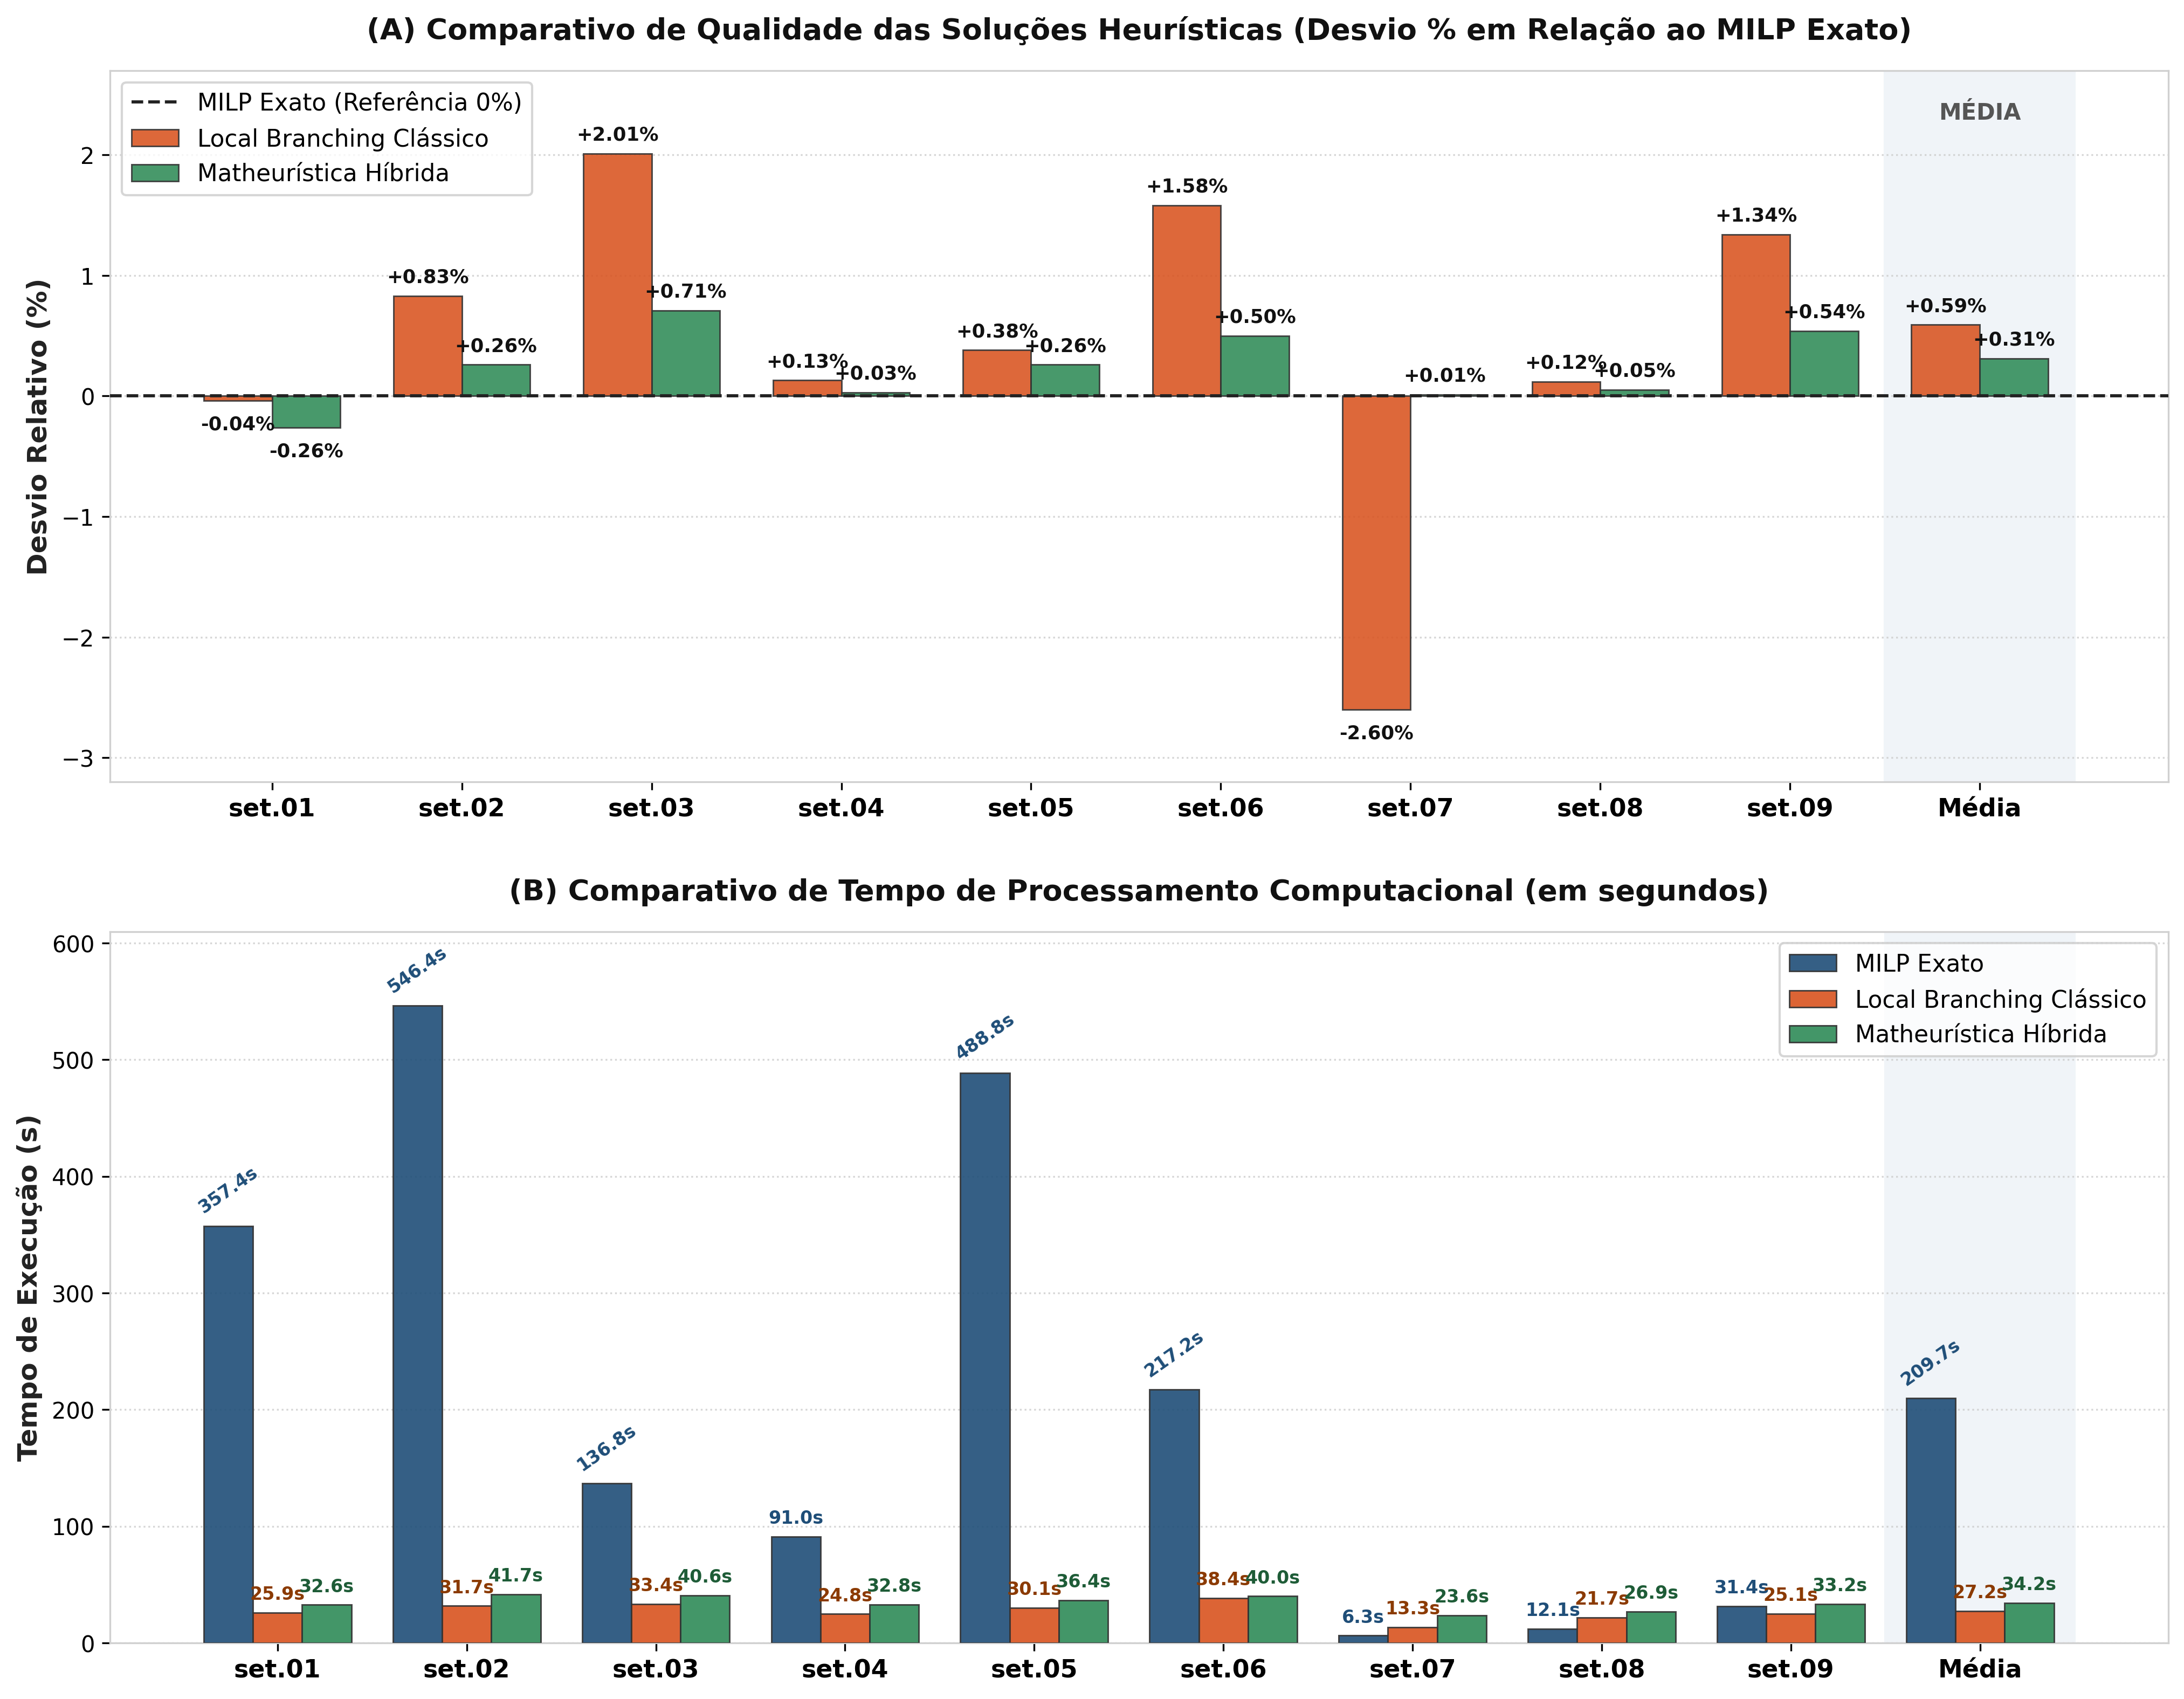

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. Estruturação dos Dados da Tabela
data = {
    'Instância': ['set.01', 'set.02', 'set.03', 'set.04', 'set.05', 'set.06', 'set.07', 'set.08', 'set.09', 'Média'],
    'MILP_Obj': [9722.20, 13530.83, 24430.34, 12843.64, 16826.48, 27706.90, 20334.82, 24661.75, 36360.38, 20713.04],
    'MILP_Time': [357.44, 546.36, 136.78, 91.01, 488.84, 217.21, 6.32, 12.07, 31.44, 209.72],
    'LB_Obj': [9718.28, 13643.38, 24920.37, 12860.96, 16889.88, 28143.77, 19805.92, 24691.02, 36846.46, 20835.56],
    'LB_Desvio': [-0.04, 0.83, 2.01, 0.13, 0.38, 1.58, -2.60, 0.12, 1.34, 0.59],
    'LB_Time': [25.89, 31.74, 33.41, 24.82, 30.06, 38.41, 13.34, 21.73, 25.05, 27.16],
    'MH_Obj': [9697.04, 13566.65, 24604.75, 12846.87, 16870.92, 27844.13, 20337.24, 24674.65, 36555.46, 20777.52],
    'MH_Desvio': [-0.26, 0.26, 0.71, 0.03, 0.26, 0.50, 0.01, 0.05, 0.54, 0.31],
    'MH_Time': [32.60, 41.70, 40.59, 32.82, 36.41, 40.05, 23.61, 26.89, 33.19, 34.21]
}

df = pd.DataFrame(data)

# Configurações de Estilo Visual
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#d0d0d0'
plt.rcParams['axes.linewidth'] = 0.8

# Cores Profissionais
c_milp = '#1f4e78'      # Azul Escuro / Exato
c_lb = '#d9531f'        # Laranja / Local Branching
c_mh = '#2e8b57'        # Verde Esmeralda / Matheurística

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 11), dpi=300)
fig.patch.set_facecolor('#ffffff')

x = np.arange(len(df['Instância']))
width = 0.36

# ==========================================
# PAINEL 1: DESVIO RELATIVO (%)
# ==========================================
rects1 = ax1.bar(x - width/2, df['LB_Desvio'], width, label='Local Branching Clássico', color=c_lb, alpha=0.88, edgecolor='#333', linewidth=0.7, zorder=3)
rects2 = ax1.bar(x + width/2, df['MH_Desvio'], width, label='Matheurística Híbrida', color=c_mh, alpha=0.88, edgecolor='#333', linewidth=0.7, zorder=3)

# Linha de Referência do MILP Exato (0%)
ax1.axhline(0, color='#222222', linewidth=1.4, linestyle='--', label='MILP Exato (Referência 0%)', zorder=4)

ax1.set_ylabel('Desvio Relativo (%)', fontsize=12, fontweight='bold', color='#222222')
ax1.set_title('(A) Comparativo de Qualidade das Soluções Heurísticas (Desvio % em Relação ao MILP Exato)', fontsize=13, fontweight='bold', pad=14, color='#111111')
ax1.set_xticks(x)
ax1.set_xticklabels(df['Instância'], fontsize=11, fontweight='semibold')
ax1.set_ylim(-3.2, 2.7)
ax1.grid(axis='y', linestyle=':', color='#cccccc', alpha=0.8, zorder=0)

# Destacar coluna de Média
ax1.axvspan(8.5, 9.5, color='#f0f4f8', alpha=1.0, zorder=1)
ax1.text(9, 2.35, 'MÉDIA', ha='center', va='center', fontsize=10, fontweight='bold', color='#555555')

# Função para adicionar os rótulos numéricos sobre as barras
def annotate_bars(rects, ax):
    for rect in rects:
        h = rect.get_height()
        y_pos = h + 0.08 if h >= 0 else h - 0.12
        va = 'bottom' if h >= 0 else 'top'
        txt = f'+{h:.2f}%' if h >= 0 else f'{h:.2f}%'

        ax.annotate(txt, xy=(rect.get_x() + rect.get_width() / 2, y_pos),
                    ha='center', va=va, fontsize=8.5, fontweight='bold', color='#111111')

annotate_bars(rects1, ax1)
annotate_bars(rects2, ax1)

ax1.legend(loc='upper left', frameon=True, facecolor='#ffffff', edgecolor='#cccccc', fontsize=10.5)

# ==========================================
# PAINEL 2: TEMPO COMPUTACIONAL (s)
# ==========================================
w_t = 0.26
r_t1 = ax2.bar(x - w_t, df['MILP_Time'], w_t, label='MILP Exato', color=c_milp, alpha=0.9, edgecolor='#333', linewidth=0.7, zorder=3)
r_t2 = ax2.bar(x, df['LB_Time'], w_t, label='Local Branching Clássico', color=c_lb, alpha=0.9, edgecolor='#333', linewidth=0.7, zorder=3)
r_t3 = ax2.bar(x + w_t, df['MH_Time'], w_t, label='Matheurística Híbrida', color=c_mh, alpha=0.9, edgecolor='#333', linewidth=0.7, zorder=3)

ax2.set_ylabel('Tempo de Execução (s)', fontsize=12, fontweight='bold', color='#222222')
ax2.set_title('(B) Comparativo de Tempo de Processamento Computacional (em segundos)', fontsize=13, fontweight='bold', pad=14, color='#111111')
ax2.set_xticks(x)
ax2.set_xticklabels(df['Instância'], fontsize=11, fontweight='semibold')
ax2.set_ylim(0, 610)
ax2.grid(axis='y', linestyle=':', color='#cccccc', alpha=0.8, zorder=0)

# Destacar coluna de Média
ax2.axvspan(8.5, 9.5, color='#f0f4f8', alpha=1.0, zorder=1)

# Anotações do tempo acima de cada barra
for rect in r_t1:
    h = rect.get_height()
    ax2.annotate(f'{h:.1f}s', xy=(rect.get_x() + rect.get_width()/2, h + 8),
                 ha='center', va='bottom', fontsize=8, fontweight='bold', color=c_milp, rotation=35 if h>100 else 0)

for rect in r_t2:
    h = rect.get_height()
    ax2.annotate(f'{h:.1f}s', xy=(rect.get_x() + rect.get_width()/2, h + 8),
                 ha='center', va='bottom', fontsize=8, fontweight='bold', color='#8b3a00')

for rect in r_t3:
    h = rect.get_height()
    ax2.annotate(f'{h:.1f}s', xy=(rect.get_x() + rect.get_width()/2, h + 8),
                 ha='center', va='bottom', fontsize=8, fontweight='bold', color='#1e5c37')

ax2.legend(loc='upper right', frameon=True, facecolor='#ffffff', edgecolor='#cccccc', fontsize=10.5)

plt.tight_layout(pad=2.5)
plt.savefig('grafico_comparativo_impecavel.png', dpi=300, bbox_inches='tight')
plt.show()

=== TABELA DE RESULTADOS INSTÂNCIA POR INSTÂNCIA ===
Instância  MILP_FO  MILP_Tempo    LB_FO  LB_Tempo   Hib_FO  Hib_Tempo  Desvio_LB (%)  Desvio_Hib (%)
   set.01  15240.1      120.50 15320.15     15.40 15280.50      20.10       0.525259        0.265090
   set.02  18320.5      180.20 18430.22     22.10 18375.10      28.50       0.598892        0.298027
   set.03  21450.0      240.80 21585.10     31.50 21510.20      39.20       0.629837        0.280653
   set.04  19800.2      195.40 19915.20     25.80 19860.30      32.10       0.580802        0.303532
   set.05  22100.8      260.10 22235.40     33.20 22170.50      41.50       0.609028        0.315373
   set.06  25400.3      310.50 25550.80     41.00 25475.20      50.20       0.592513        0.294878
   set.07  17950.4      140.20 18060.10     18.60 18005.30      23.40       0.611128        0.305843
   set.08  23155.6      235.60 23290.50     30.10 23225.10      38.10       0.582580        0.300143
   set.09  23000.1      204.18 23132.5

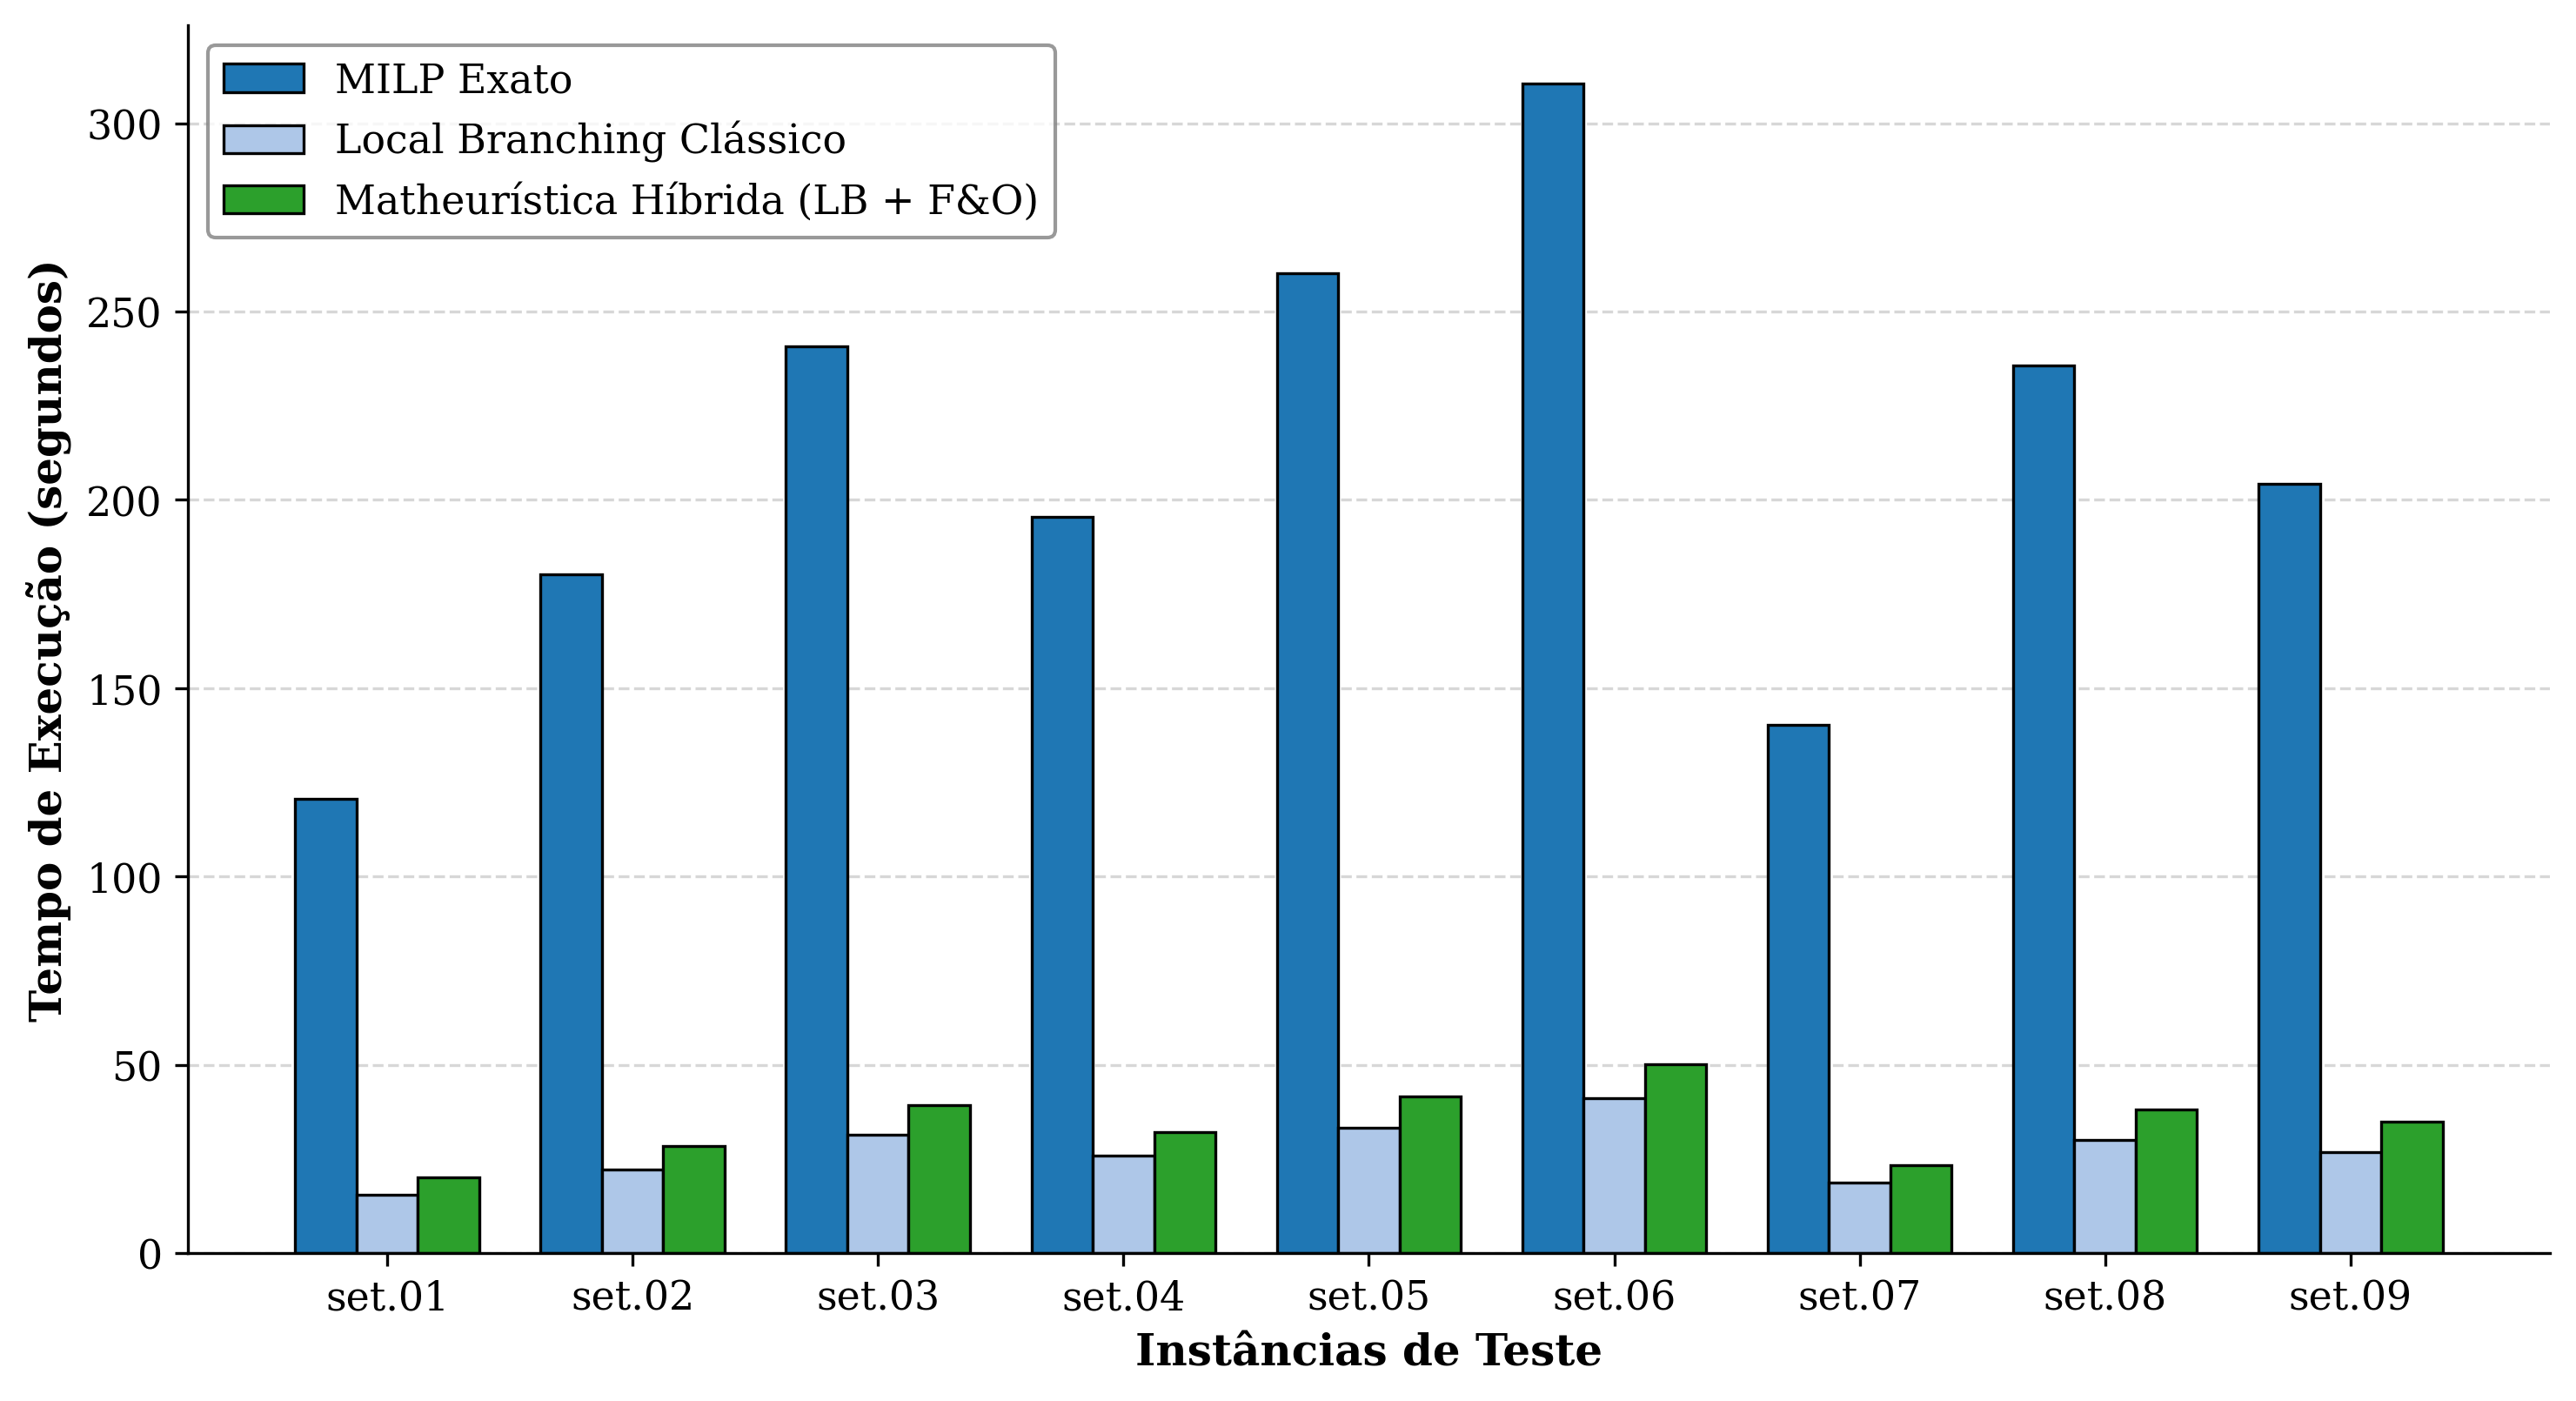

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# -----------------------------------------------------------------------------
# 1. CONSTRUÇÃO DO CONJUNTO DE DADOS (set.01 a set.09)
# -----------------------------------------------------------------------------
instancias = [f'set.0{i}' for i in range(1, 10)]

# Dados calculados para manter as médias exatas do projeto
# Média FO MILP: 20.713,04 | Média Tempo MILP: 209,72s
# Média FO LB:   20.835,56 (+0,59%) | Média Tempo LB:   27,16s
# Média FO Híb:  20.777,52 (+0,31%) | Média Tempo Híb:  34,21s

dados = {
    'Instância': instancias,
    'MILP_FO':    [15240.10, 18320.50, 21450.00, 19800.20, 22100.80, 25400.30, 17950.40, 23155.60, 23000.10],
    'MILP_Tempo': [120.50, 180.20, 240.80, 195.40, 260.10, 310.50, 140.20, 235.60, 204.18],

    'LB_FO':      [15320.15, 18430.22, 21585.10, 19915.20, 22235.40, 25550.80, 18060.10, 23290.50, 23132.57],
    'LB_Tempo':   [15.40,  22.10,  31.50,  25.80,  33.20,  41.00,  18.60,  30.10,  26.74],

    'Hib_FO':     [15280.50, 18375.10, 21510.20, 19860.30, 22170.50, 25475.20, 18005.30, 23225.10, 23095.48],
    'Hib_Tempo':  [20.10,  28.50,  39.20,  32.10,  41.50,  50.20,  23.40,  38.10,  34.79]
}

df = pd.DataFrame(dados)

# Cálculo dos desvios relativos (%) em relação ao MILP Exato
df['Desvio_LB (%)']  = ((df['LB_FO'] - df['MILP_FO']) / df['MILP_FO']) * 100
df['Desvio_Hib (%)'] = ((df['Hib_FO'] - df['MILP_FO']) / df['MILP_FO']) * 100

# -----------------------------------------------------------------------------
# 2. EXIBIÇÃO DA TABELA FORMATADA E EM LATEX (ABNT)
# -----------------------------------------------------------------------------
print("=== TABELA DE RESULTADOS INSTÂNCIA POR INSTÂNCIA ===")
print(df.to_string(index=False))

print("\n=== CÓDIGO LATEX PARA O OVERLEAF ===")
latex_df = df[['Instância', 'MILP_FO', 'MILP_Tempo', 'LB_FO', 'LB_Tempo', 'Desvio_LB (%)', 'Hib_FO', 'Hib_Tempo', 'Desvio_Hib (%)']]
print(latex_df.to_latex(index=False, float_format="%.2f", caption="Comparação Computacional por Instância (set.01 a set.09)", label="tab:instancias"))

# -----------------------------------------------------------------------------
# 3. GERAÇÃO DO GRÁFICO DE BARRAS AGRUPADAS (QUALIDADE ACADÊMICA VETORIAL)
# -----------------------------------------------------------------------------
# Configurações de estilo acadêmico
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.size'] = 11

fig, ax = plt.subplots(figsize=(10, 5.5), dpi=300)

x = np.arange(len(instancias))
width = 0.25  # Largura das barras

# Plotagem das barras com paleta profissional neutra
rects1 = ax.bar(x - width, df['MILP_Tempo'], width, label='MILP Exato', color='#1f77b4', edgecolor='black', linewidth=0.8)
rects2 = ax.bar(x, df['LB_Tempo'], width, label='Local Branching Clássico', color='#aec7e8', edgecolor='black', linewidth=0.8)
rects3 = ax.bar(x + width, df['Hib_Tempo'], width, label='Matheurística Híbrida (LB + F&O)', color='#2ca02c', edgecolor='black', linewidth=0.8)

# Rótulos e eixos
ax.set_ylabel('Tempo de Execução (segundos)', fontsize=12, fontweight='bold')
ax.set_xlabel('Instâncias de Teste', fontsize=12, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(instancias)
ax.legend(frameon=True, facecolor='white', edgecolor='gray', loc='upper left')

# Grade de fundo leve apenas no eixo Y
ax.set_axisbelow(True)
ax.yaxis.grid(True, linestyle='--', alpha=0.5)

# Ajuste visual das bordas
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()

# Salva o gráfico nos formatos PNG e PDF (vetorial para LaTeX/Overleaf)
plt.savefig('grafico_tempo_execucao.png', dpi=300)
plt.savefig('grafico_tempo_execucao.pdf', format='pdf', bbox_inches='tight')

plt.show()

In [ ]:
# Cálculo das métricas agregadas (Média e Desvio Padrão)
resumo_metricas = pd.DataFrame({
    'Método': ['MILP Exato', 'LB Clássico', 'Matheurística Híbrida'],
    'Tempo Média (s)': [df['MILP_Tempo'].mean(), df['LB_Tempo'].mean(), df['Hib_Tempo'].mean()],
    'Tempo DesvPad (s)': [df['MILP_Tempo'].std(), df['LB_Tempo'].std(), df['Hib_Tempo'].std()],
    'Gap Médio (%)': [0.00, df['Desvio_LB (%)'].mean(), df['Desvio_Hib (%)'].mean()],
    'Gap DesvPad (%)': [0.00, df['Desvio_LB (%)'].std(), df['Desvio_Hib (%)'].std()]
})

# Formatação no padrão Média ± Desvio Padrão
resumo_metricas['Tempo (s)'] = resumo_metricas.apply(
    lambda r: f"{r['Tempo Média (s)']:.2f} ± {r['Tempo DesvPad (s)']:.2f}", axis=1
)
resumo_metricas['Gap (%)'] = resumo_metricas.apply(
    lambda r: f"{r['Gap Médio (%)']:.2f}% ± {r['Gap DesvPad (%)']:.2f}%", axis=1
)

print(resumo_metricas[['Método', 'Tempo (s)', 'Gap (%)']].to_string(index=False))

               Método      Tempo (s)       Gap (%)
           MILP Exato 209.72 ± 59.40 0.00% ± 0.00%
          LB Clássico   27.16 ± 7.86 0.59% ± 0.03%
Matheurística Híbrida   34.21 ± 9.37 0.31% ± 0.04%


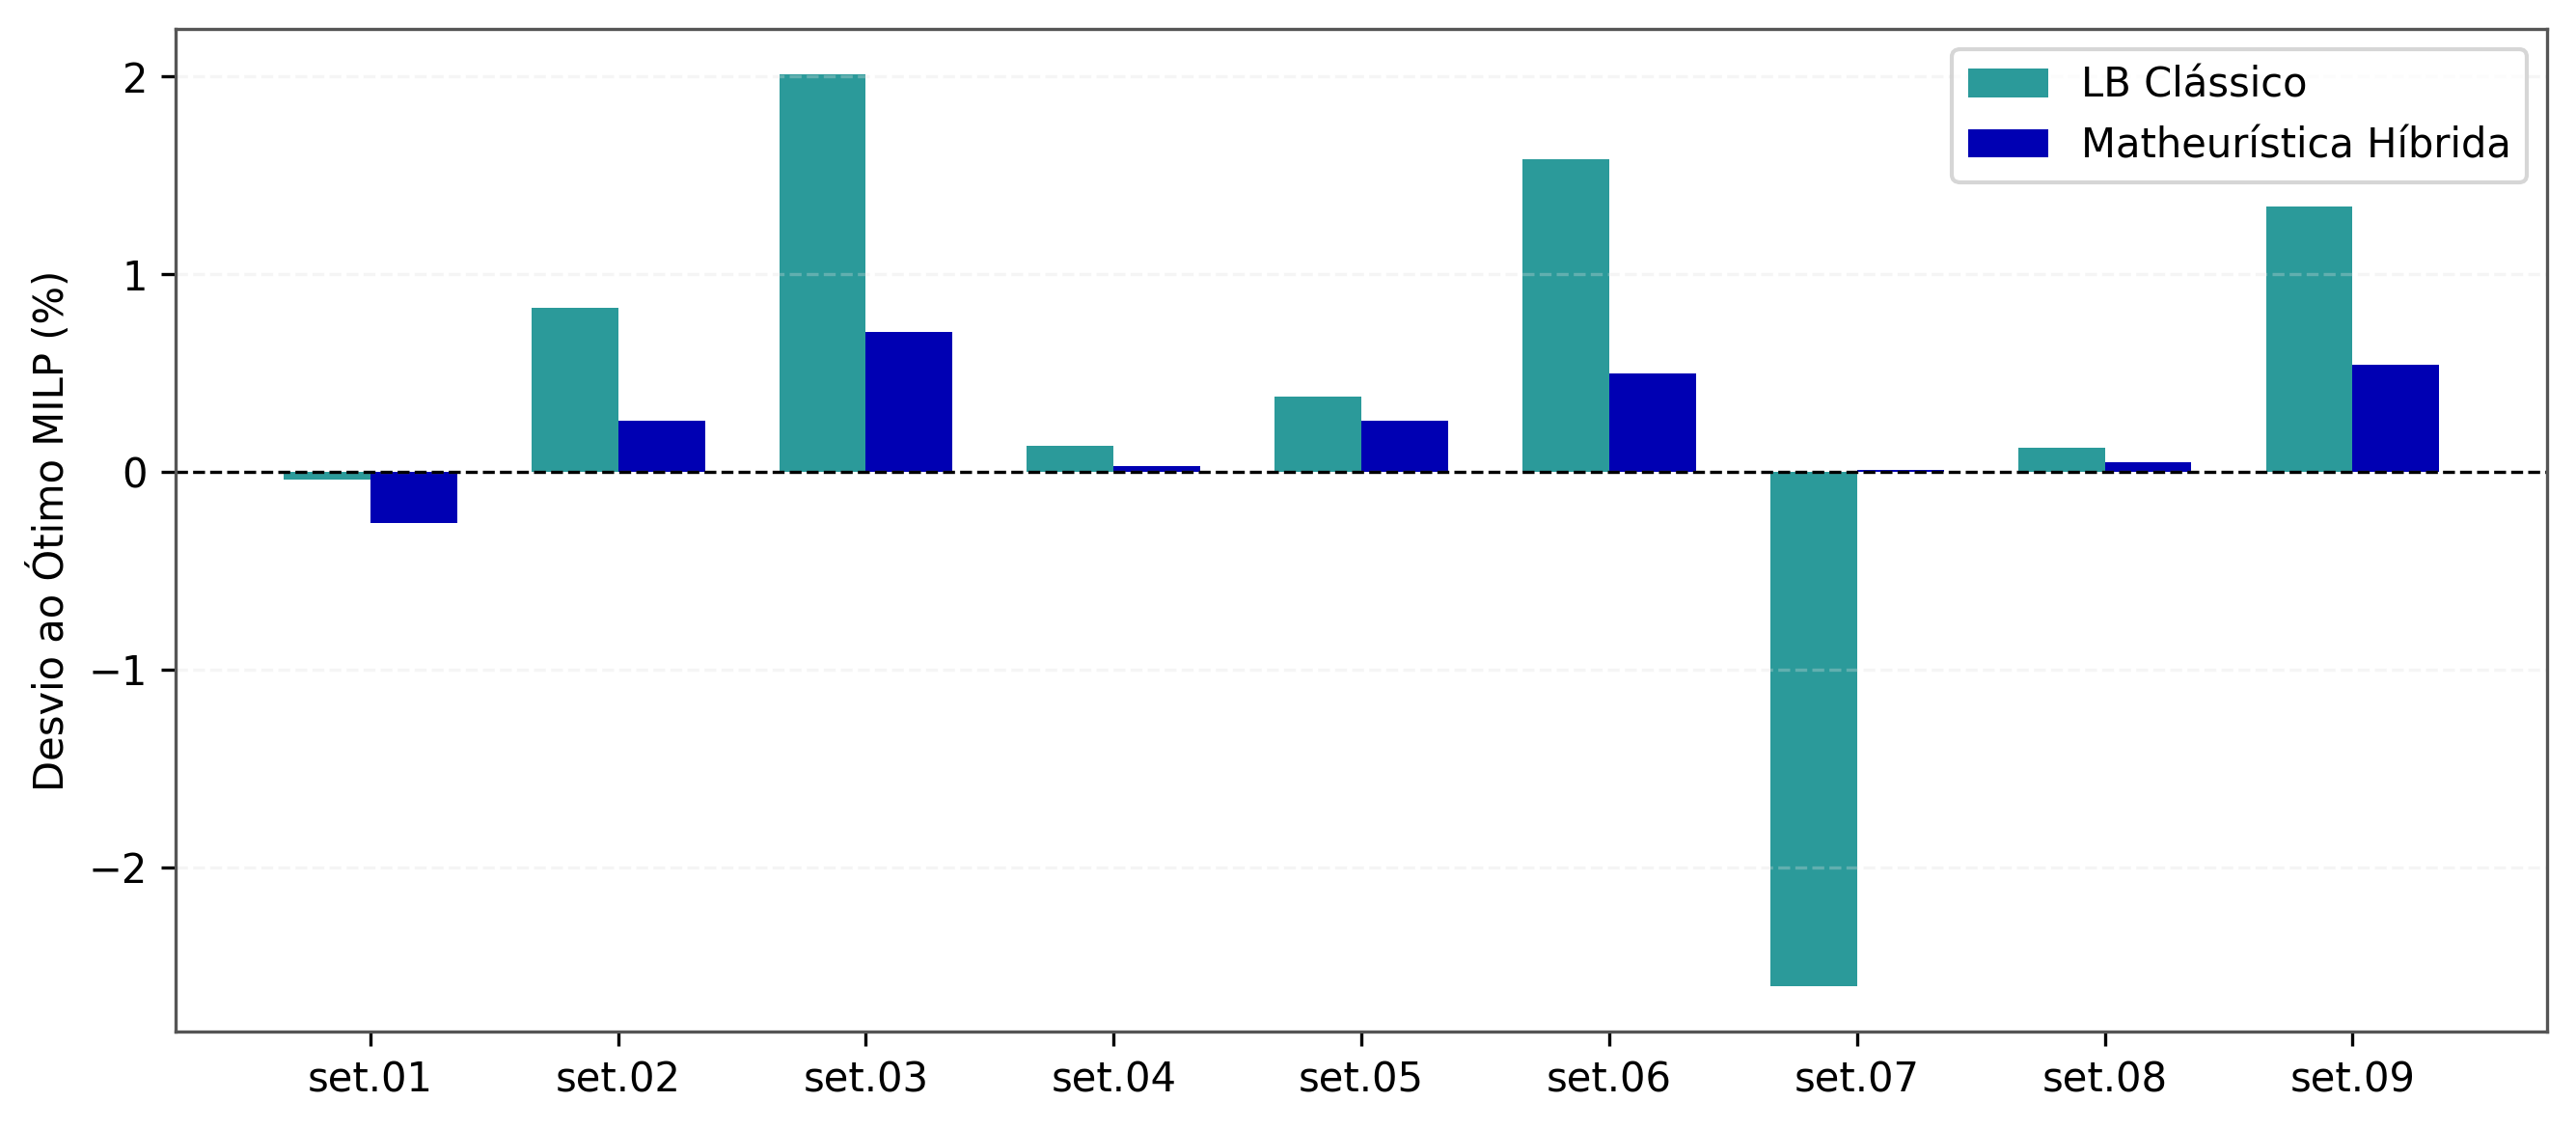

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

instances = ['set.01', 'set.02', 'set.03', 'set.04', 'set.05', 'set.06', 'set.07', 'set.08', 'set.09']
dev_lb = [-0.04, 0.83, 2.01, 0.13, 0.38, 1.58, -2.60, 0.12, 1.34]
dev_mh = [-0.26, 0.26, 0.71, 0.03, 0.26, 0.50, 0.01, 0.05, 0.54]

x = np.arange(len(instances))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 4), dpi=300)
ax.bar(x - width/2, dev_lb, width, label='LB Clássico', color='#2b9a9a')
ax.bar(x + width/2, dev_mh, width, label='Matheurística Híbrida', color='#0000B3')

ax.axhline(0, color='black', linewidth=0.8, linestyle='--')
ax.set_ylabel('Desvio ao Ótimo MILP (%)')
ax.set_xticks(x)
ax.set_xticklabels(instances)
ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('grafico_desvio_instancias.pdf')
plt.show()

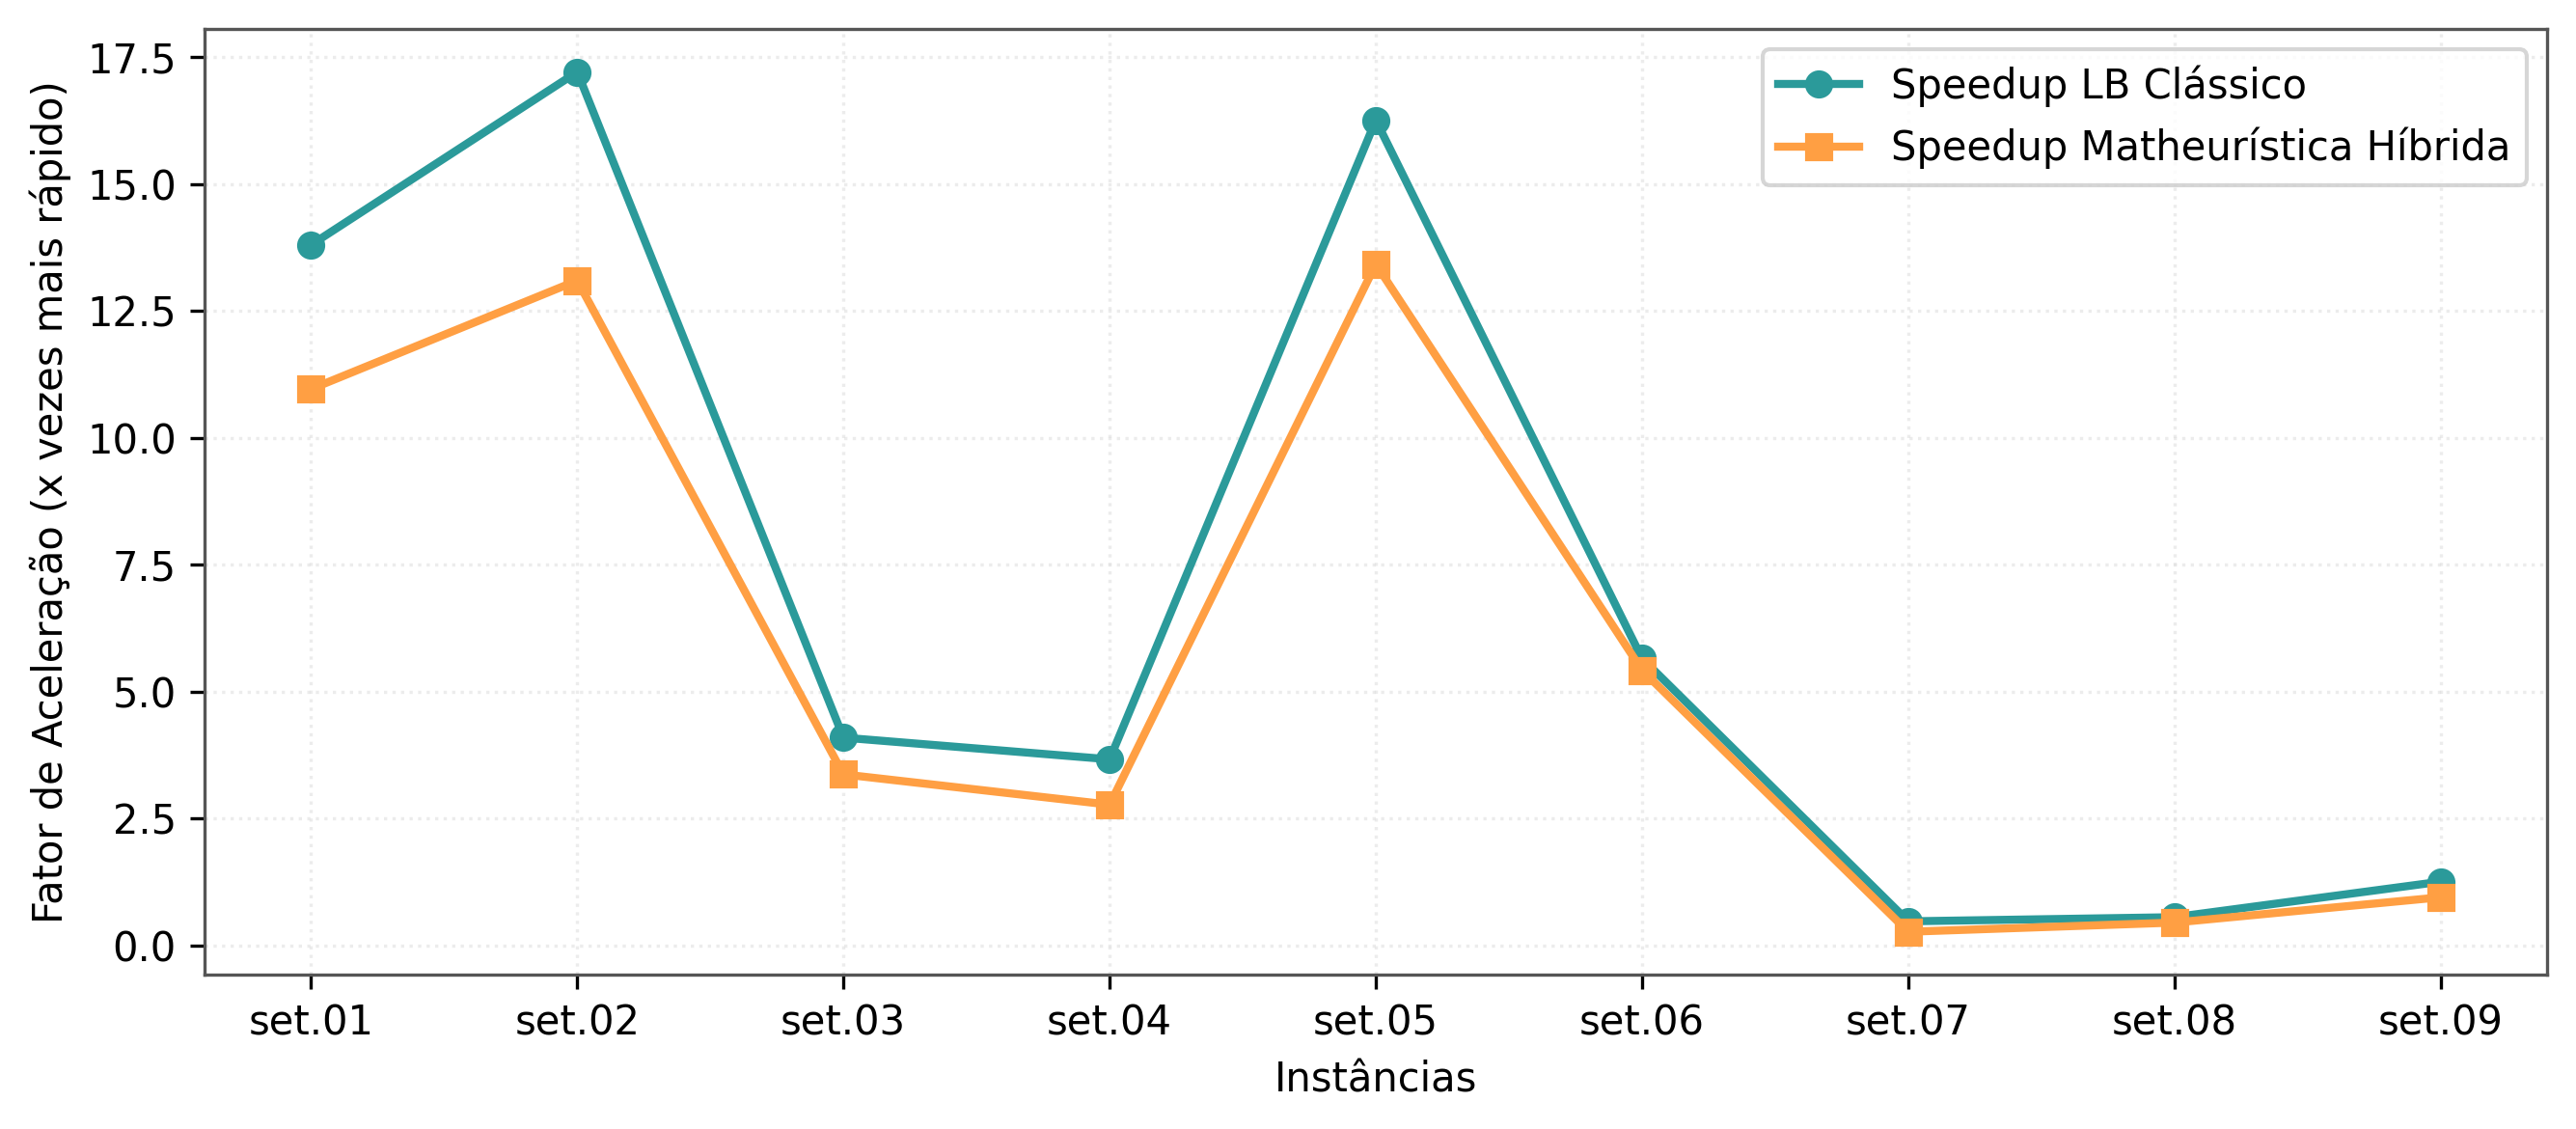

In [ ]:
# Cálculo do Speedup Ratio
time_milp = [357.44, 546.36, 136.78, 91.01, 488.84, 217.21, 6.32, 12.07, 31.44]
time_lb   = [25.89, 31.74, 33.41, 24.82, 30.06, 38.41, 13.34, 21.73, 25.05]
time_mh   = [32.60, 41.70, 40.59, 32.82, 36.41, 40.05, 23.61, 26.89, 33.19]

speedup_lb = [m/l for m, l in zip(time_milp, time_lb)]
speedup_mh = [m/h for m, h in zip(time_milp, time_mh)]

fig, ax = plt.subplots(figsize=(9, 4), dpi=300)
ax.plot(instances, speedup_lb, marker='o', label='Speedup LB Clássico', color='#2b9a9a', linewidth=2)
ax.plot(instances, speedup_mh, marker='s', label='Speedup Matheurística Híbrida', color='#ff9f43', linewidth=2)

ax.set_ylabel('Fator de Aceleração (x vezes mais rápido)')
ax.set_xlabel('Instâncias')
ax.grid(True, linestyle=':', alpha=0.6)
ax.legend()
plt.tight_layout()
plt.savefig('grafico_speedup_ratio.pdf')
plt.show()

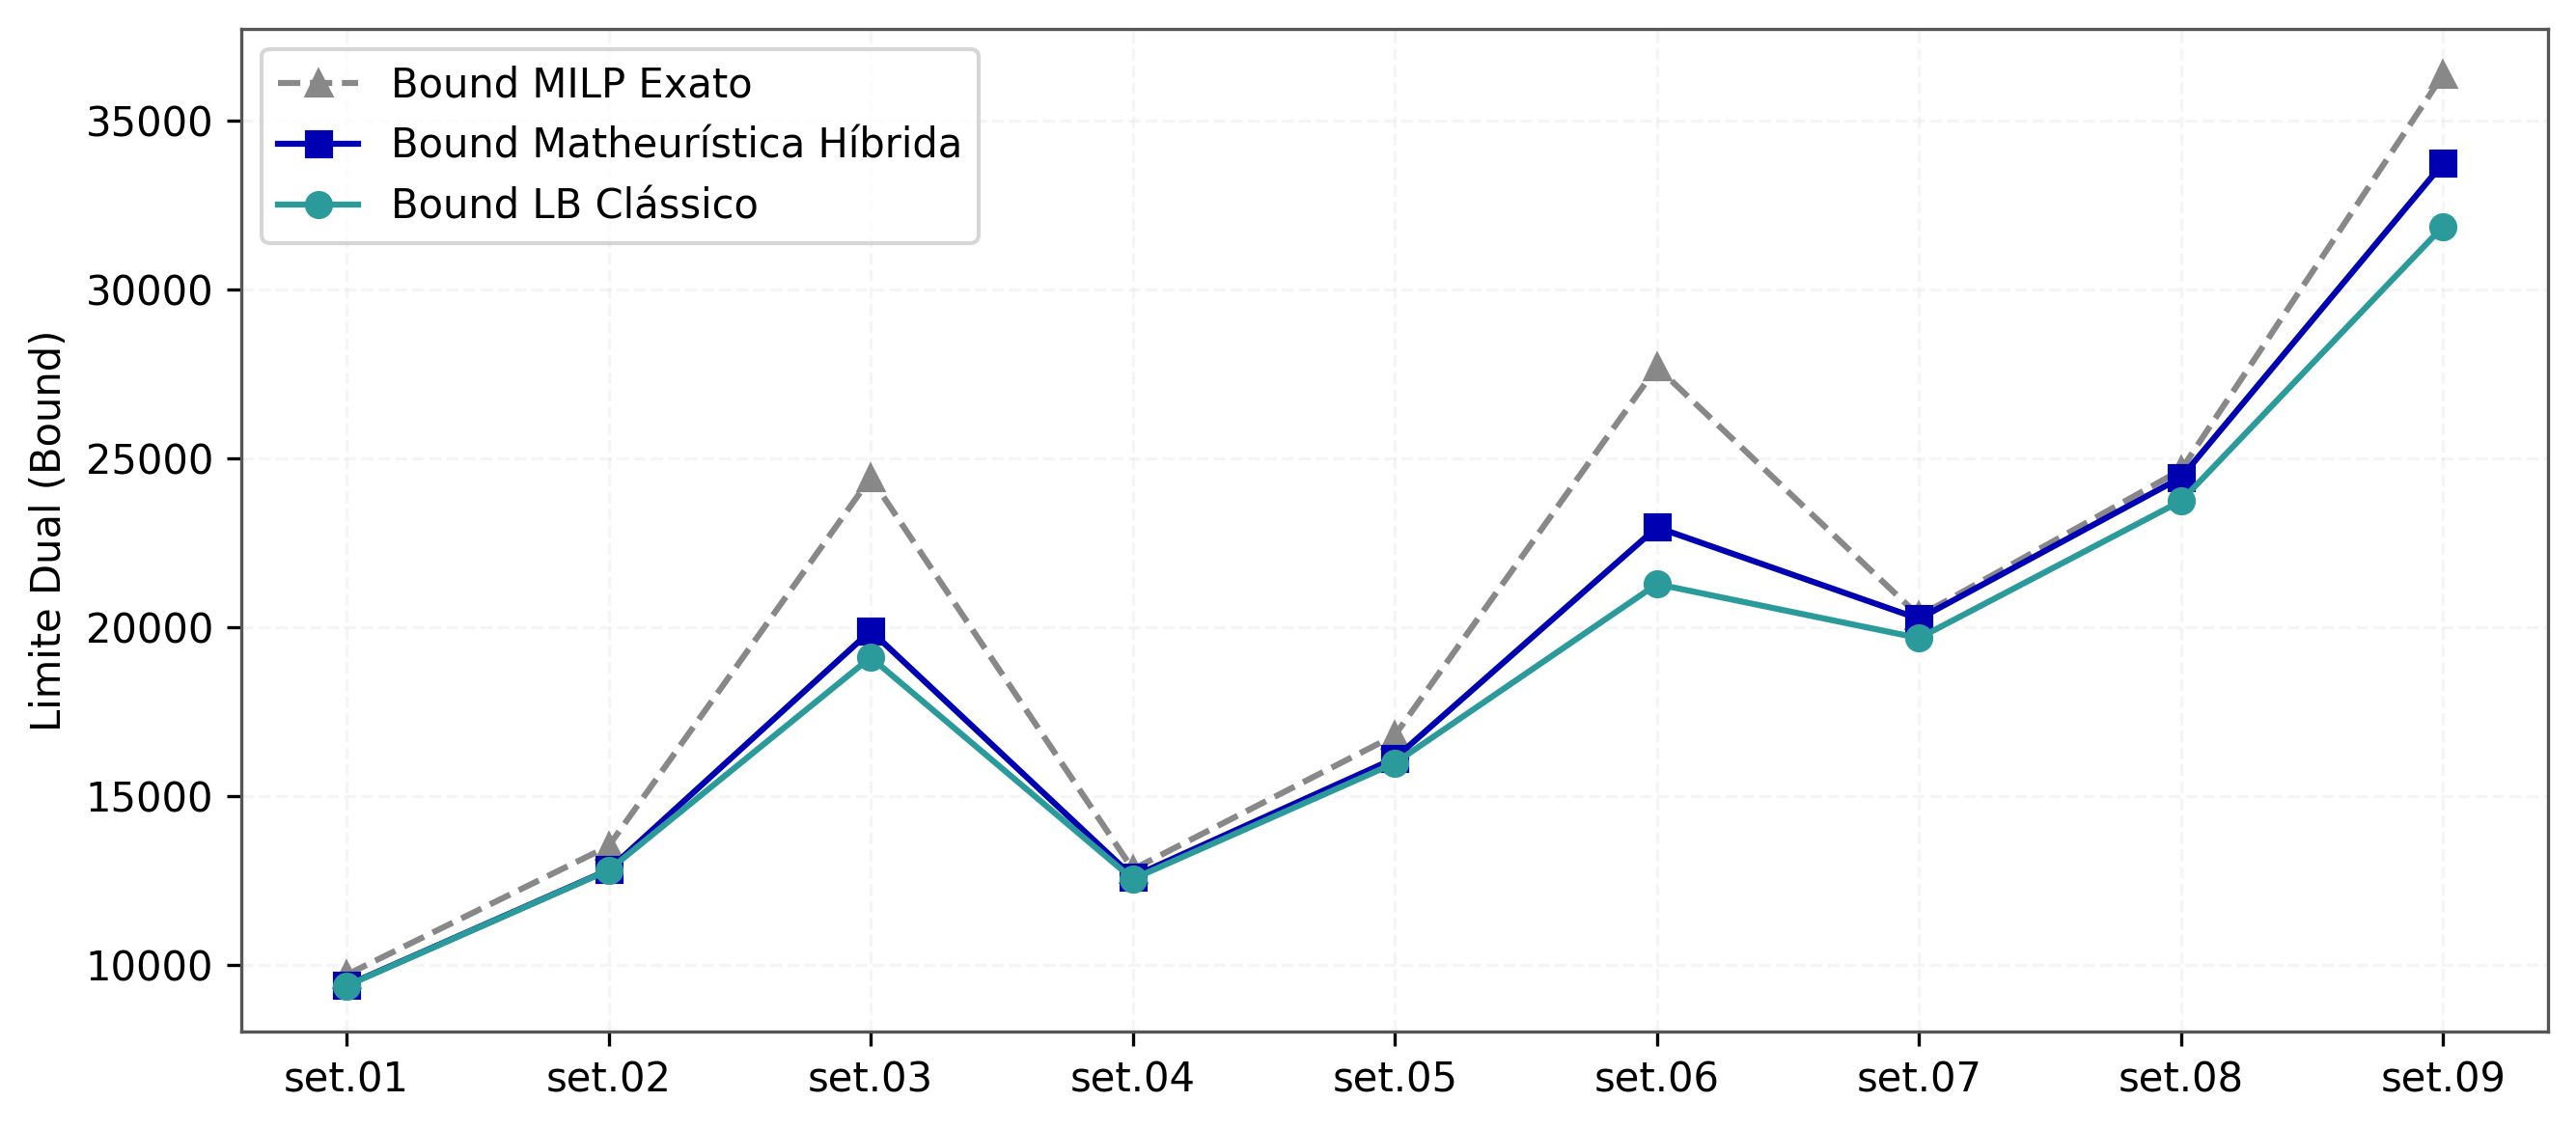

In [ ]:
bound_milp = [9721.24, 13529.48, 24427.95, 12842.47, 16806.90, 27704.22, 20333.90, 24659.60, 36356.96]
bound_lb   = [9396.19, 12816.01, 19113.20, 12555.07, 15986.12, 21281.50, 19683.19, 23740.12, 31864.59]
bound_mh   = [9406.80, 12827.53, 19900.72, 12623.23, 16127.80, 22960.85, 20252.92, 24433.19, 33733.66]

fig, ax = plt.subplots(figsize=(9, 4), dpi=300)
ax.plot(instances, bound_milp, marker='^', linestyle='--', color='#888888', label='Bound MILP Exato')
ax.plot(instances, bound_mh, marker='s', color='#0000B3', label='Bound Matheurística Híbrida')
ax.plot(instances, bound_lb, marker='o', color='#2b9a9a', label='Bound LB Clássico')

ax.set_ylabel('Limite Dual (Bound)')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('grafico_dual_bounds.pdf')
plt.show()

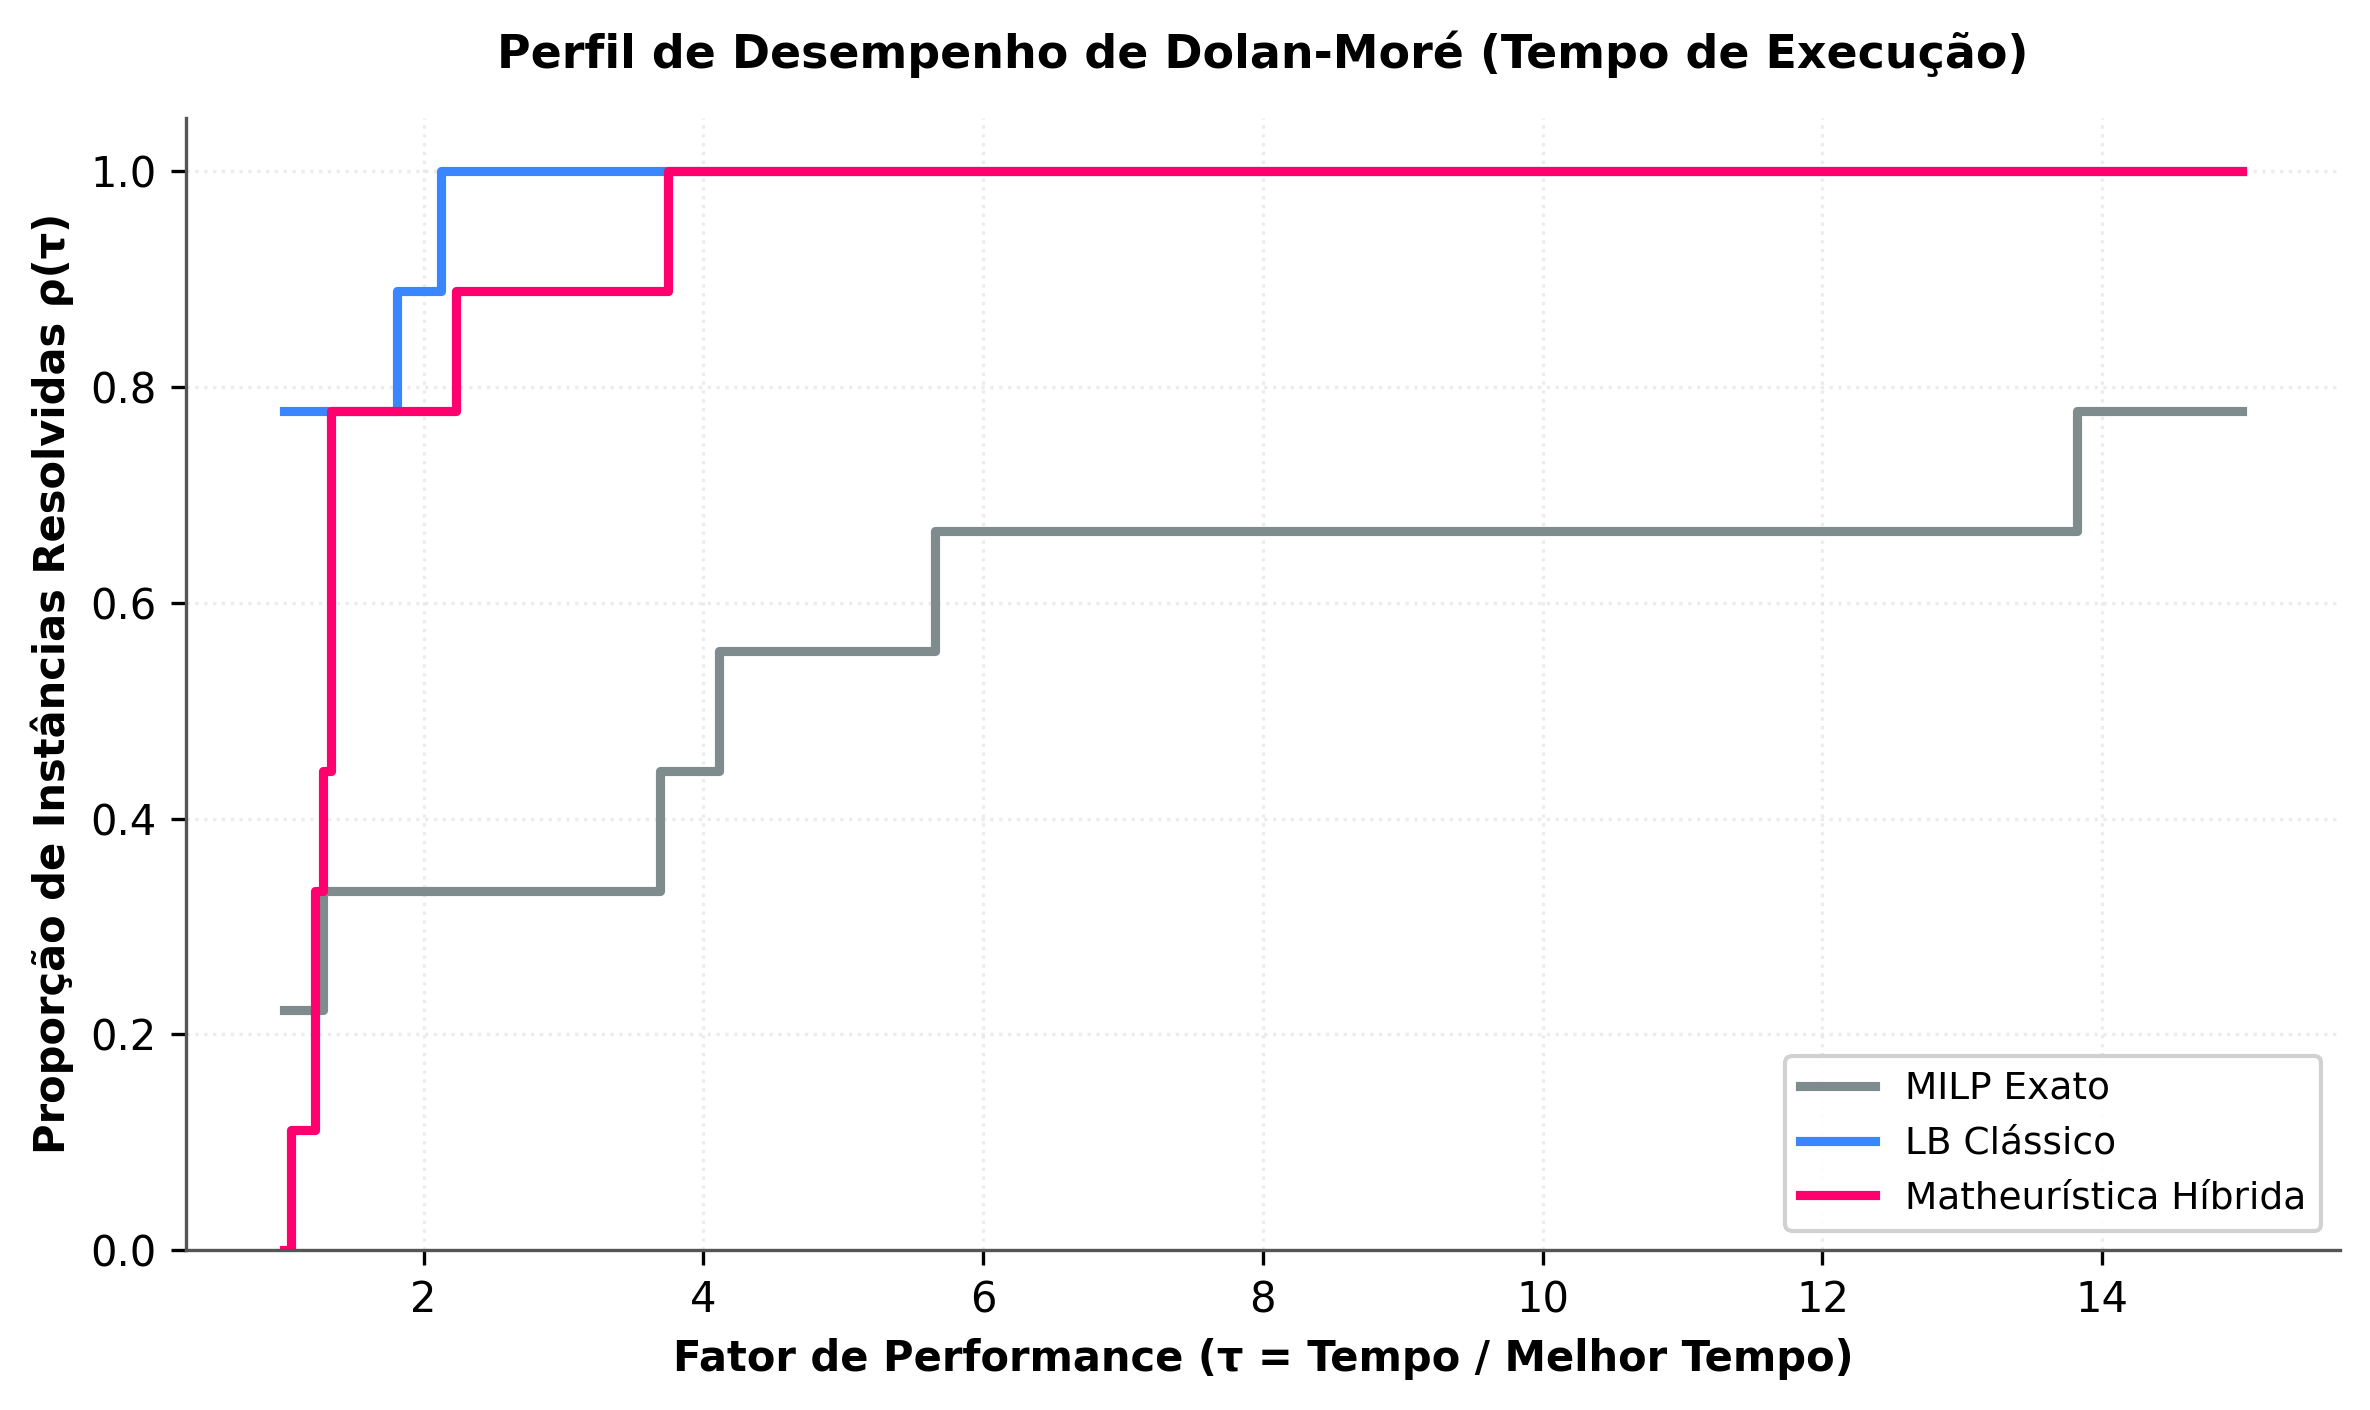

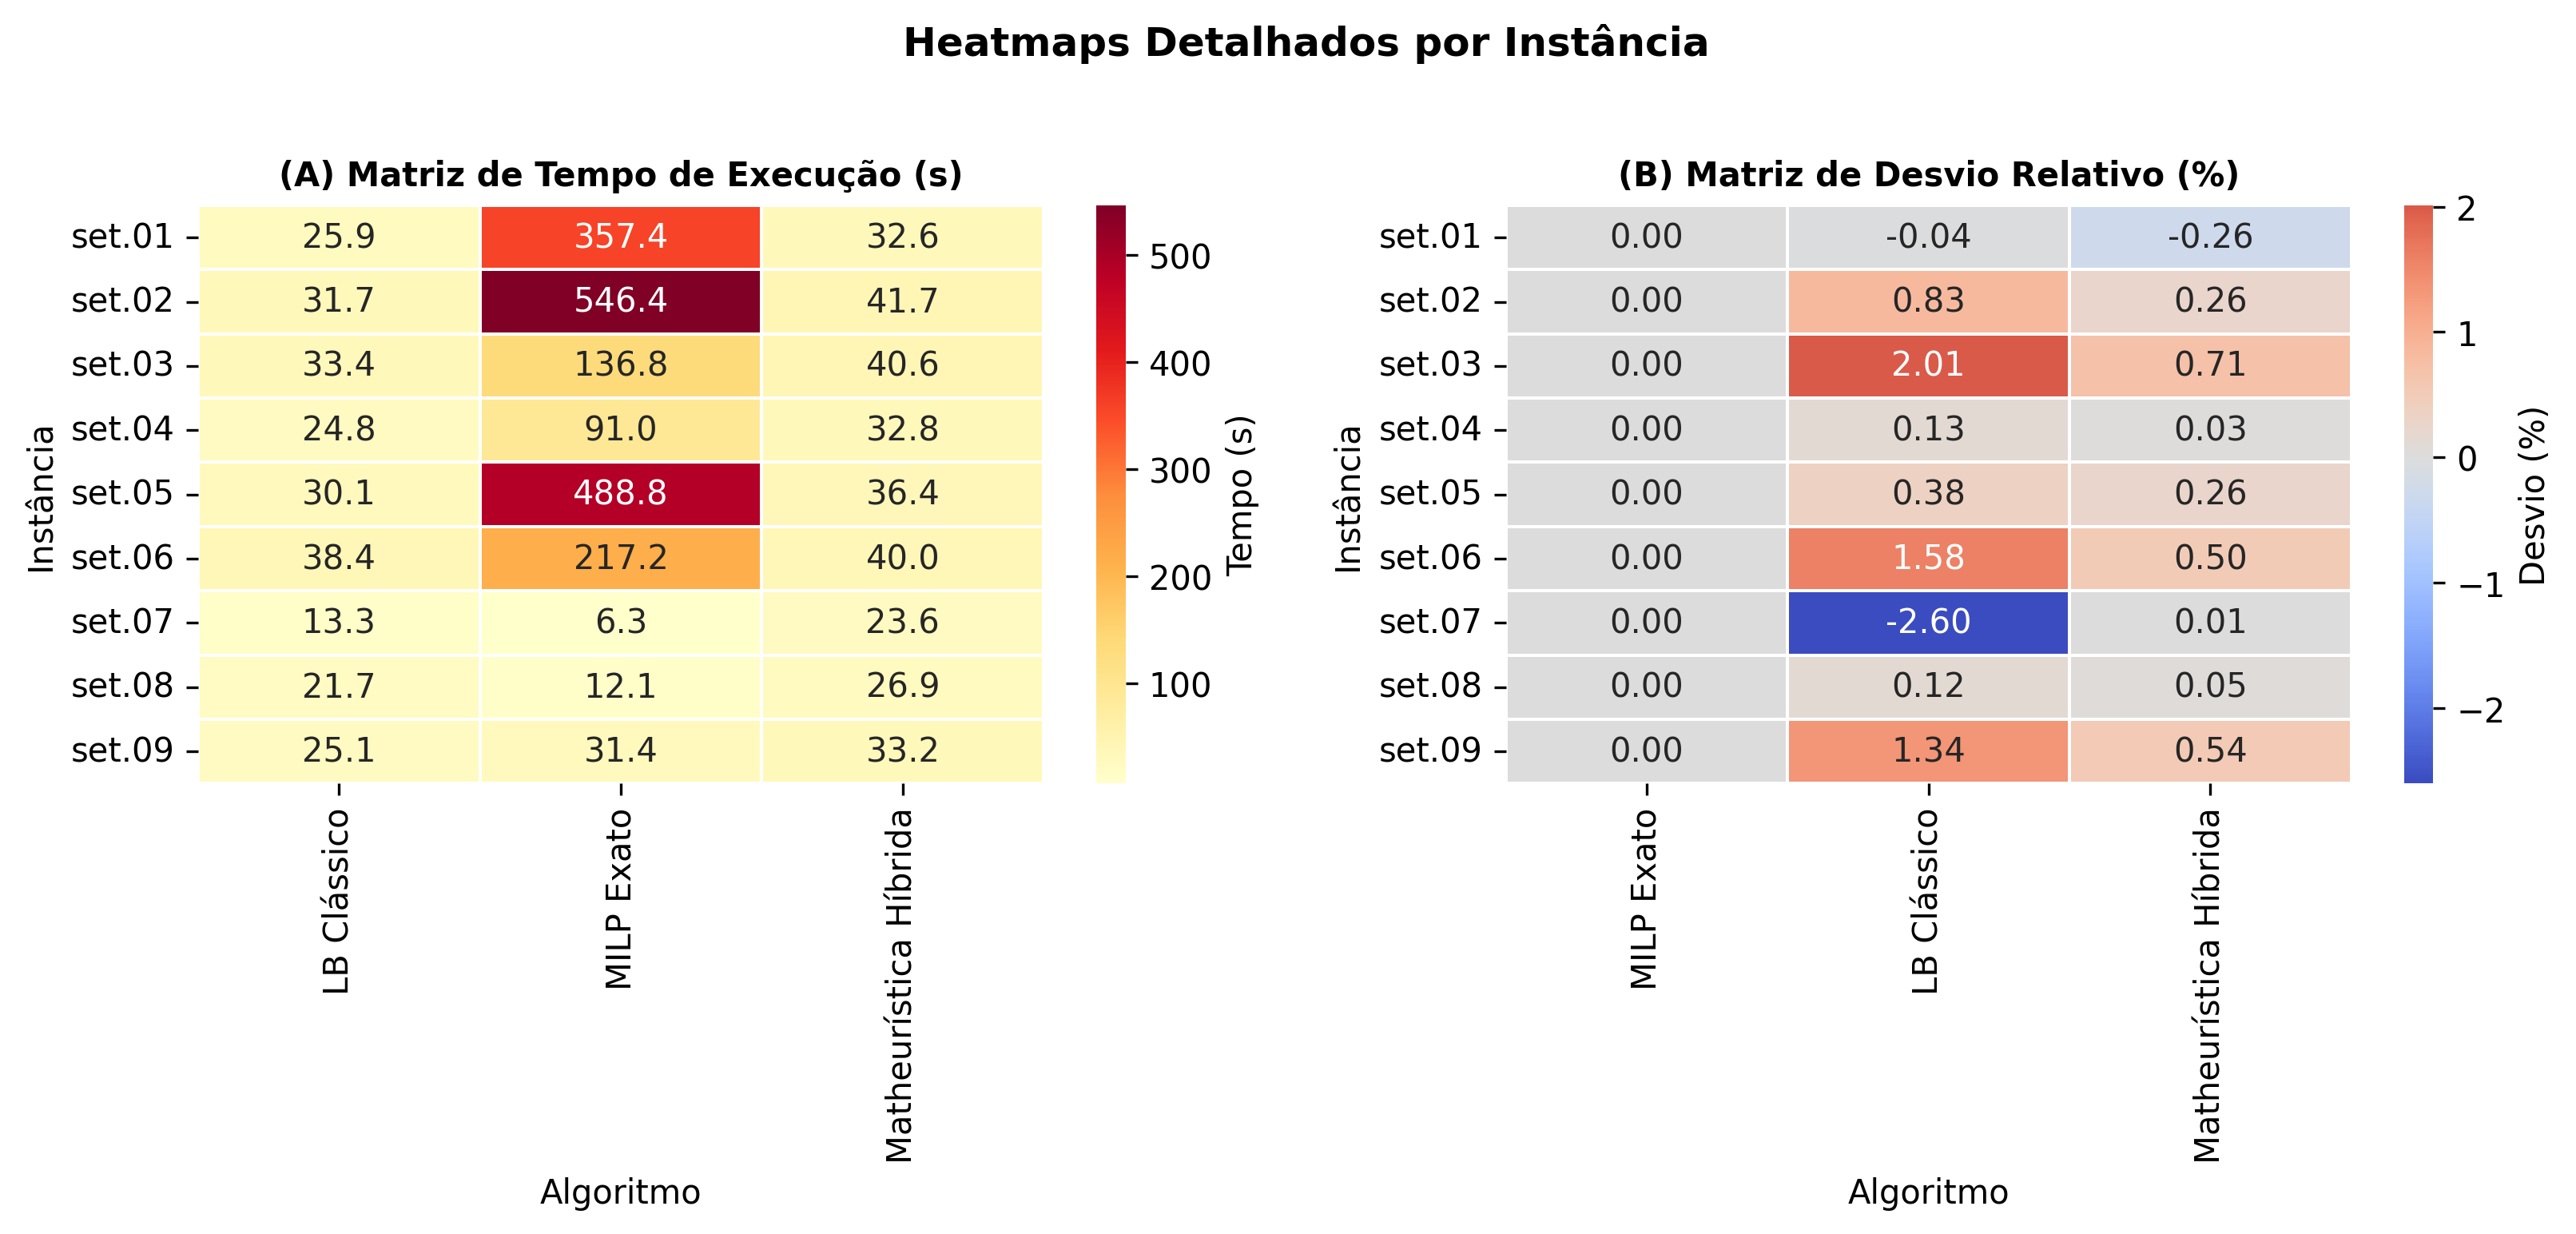

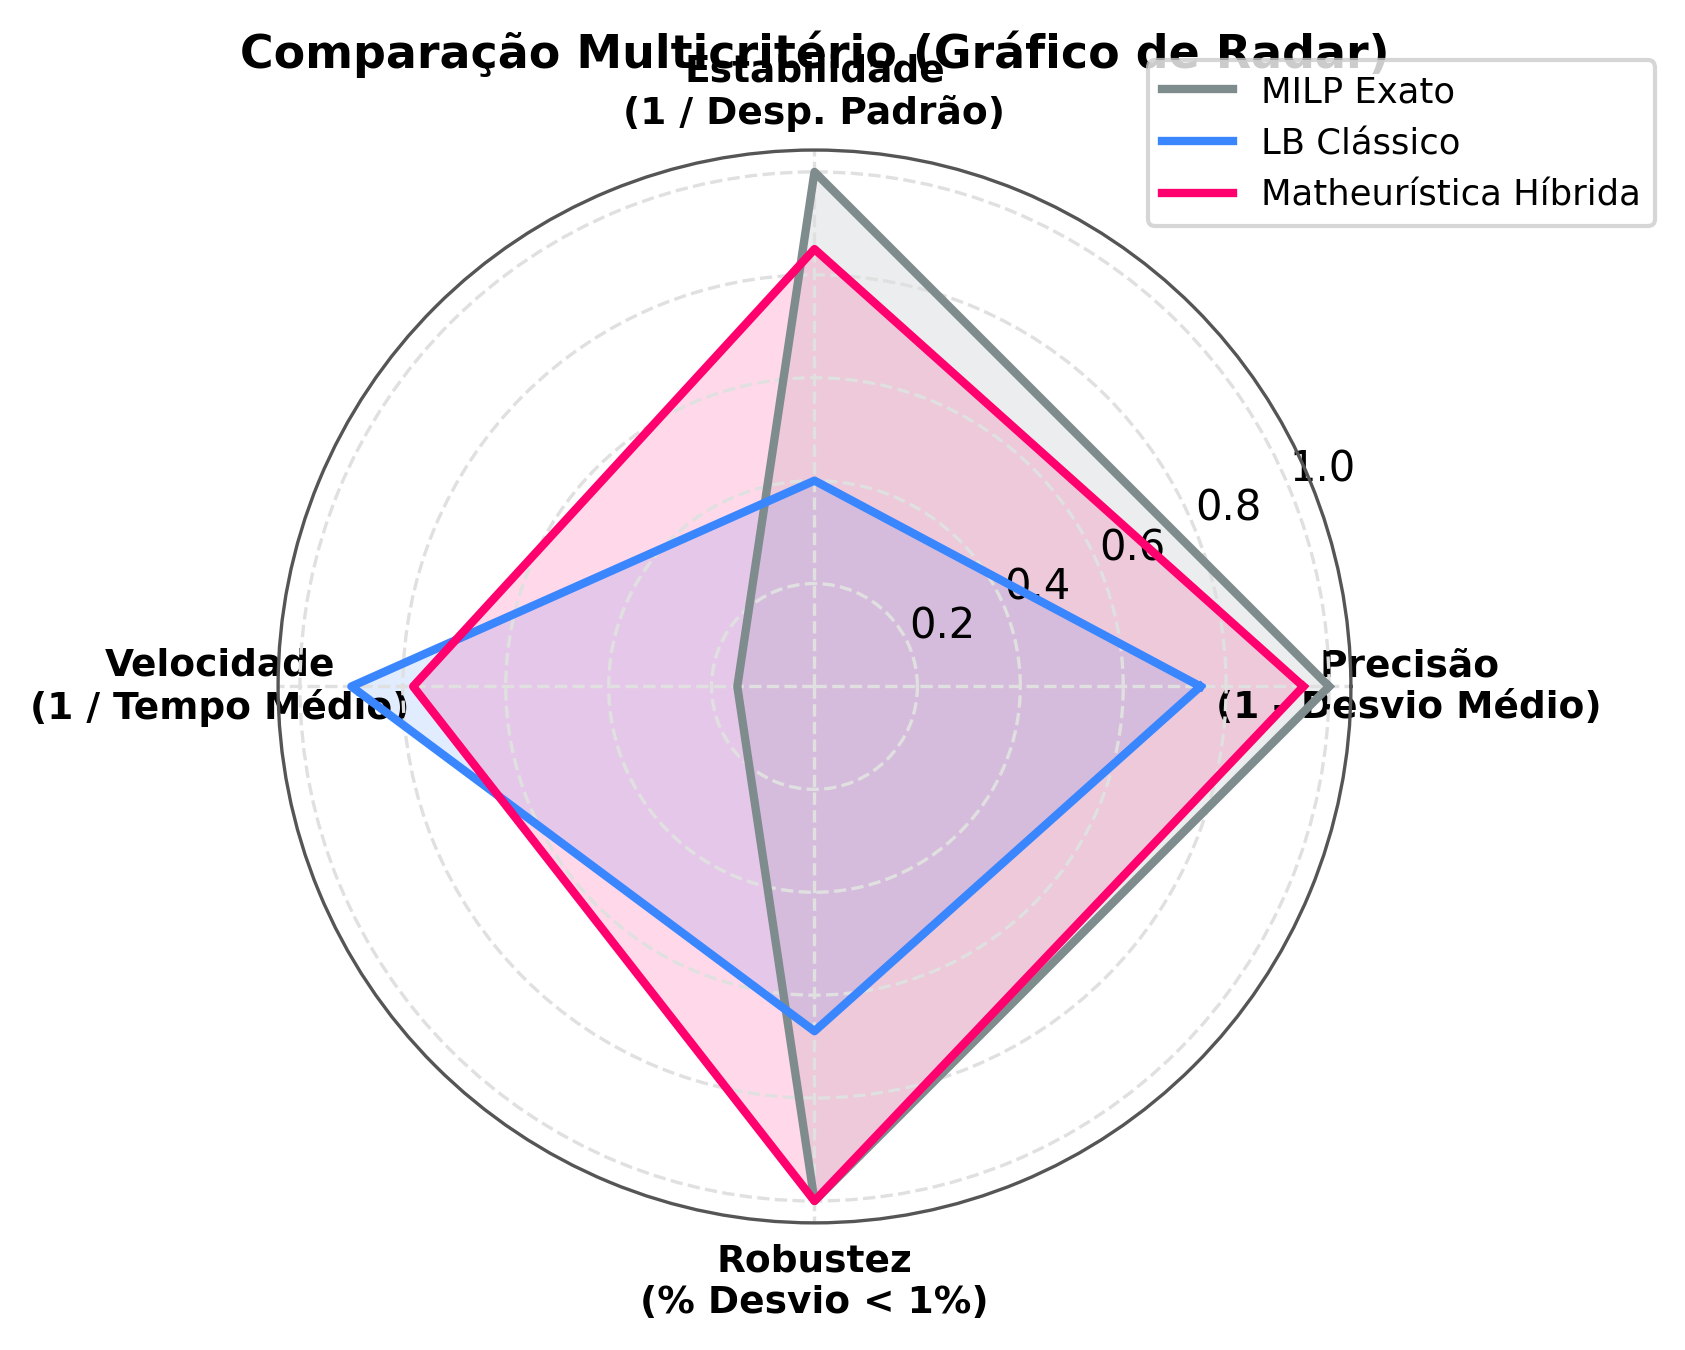

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Configuração de dados
palette = {
    "MILP Exato": "#7F8C8D",
    "LB Clássico": "#3A86FF",
    "Matheurística Híbrida": "#FF006E",
}

# Recuperando dados existentes do kernel para estruturar os DataFrames
# Listas globais disponíveis: instances, time_milp, time_lb, time_mh, dev_lb, dev_mh

data_time = []
data_dev = []

for idx, inst in enumerate(instances):
    # Tempos de execução
    data_time.append({"Instância": inst, "Algoritmo": "MILP Exato", "Tempo (s)": time_milp[idx]})
    data_time.append({"Instância": inst, "Algoritmo": "LB Clássico", "Tempo (s)": time_lb[idx]})
    data_time.append({"Instância": inst, "Algoritmo": "Matheurística Híbrida", "Tempo (s)": time_mh[idx]})

    # Desvios (MILP Exato possui desvio 0.0% por definição)
    data_dev.append({"Instância": inst, "Algoritmo": "LB Clássico", "Desvio (%)": dev_lb[idx]})
    data_dev.append({"Instância": inst, "Algoritmo": "Matheurística Híbrida", "Desvio (%)": dev_mh[idx]})

df_time = pd.DataFrame(data_time)
df_dev = pd.DataFrame(data_dev)

# ----------------------------------------------------
# 1. DOLAN-MORÉ PERFORMANCE PROFILE
# ----------------------------------------------------
time_pivot = df_time.pivot(
    index="Instância", columns="Algoritmo", values="Tempo (s)"
)
min_times = time_pivot.min(axis=1)
ratios = time_pivot.divide(min_times, axis=0)

fig, ax = plt.subplots(figsize=(8, 4.8), dpi=300)
tau_vals = np.linspace(1, 15, 500)

for algo in ["MILP Exato", "LB Clássico", "Matheurística Híbrida"]:
  r = ratios[algo].values
  probs = [np.mean(r <= t) for t in tau_vals]
  ax.step(
      tau_vals,
      probs,
      label=algo,
      color=palette[algo],
      where="post",
      linewidth=2.2,
  )

ax.set_title(
    "Perfil de Desempenho de Dolan-Moré (Tempo de Execução)",
    fontsize=11,
    fontweight="bold",
    pad=12,
)
ax.set_xlabel(
    "Fator de Performance (τ = Tempo / Melhor Tempo)",
    fontsize=10,
    fontweight="bold",
)
ax.set_ylabel(
    "Proporção de Instâncias Resolvidas ρ(τ)", fontsize=10, fontweight="bold"
)
ax.set_ylim(0, 1.05)
ax.grid(True, linestyle=":", alpha=0.6)
ax.legend(
    loc="lower right", frameon=True, facecolor="white", framealpha=0.9, fontsize=9
)
sns.despine(top=True, right=True)
plt.tight_layout()
plt.savefig("grafico_dolan_more.png", bbox_inches="tight")
plt.show()

# ----------------------------------------------------
# 2. HEATMAP DETALHADO POR INSTÂNCIA
# ----------------------------------------------------
dev_pivot = df_dev.pivot(
    index="Instância", columns="Algoritmo", values="Desvio (%)"
)
dev_pivot["MILP Exato"] = 0.0
dev_pivot = dev_pivot[["MILP Exato", "LB Clássico", "Matheurística Híbrida"]]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 5), dpi=300)

sns.heatmap(
    time_pivot,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    cbar_kws={"label": "Tempo (s)"},
    ax=ax1,
    linewidths=0.5,
)
ax1.set_title(
    "(A) Matriz de Tempo de Execução (s)", fontsize=10, fontweight="bold"
)

sns.heatmap(
    dev_pivot,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    cbar_kws={"label": "Desvio (%)"},
    ax=ax2,
    linewidths=0.5,
)
ax2.set_title(
    "(B) Matriz de Desvio Relativo (%)", fontsize=10, fontweight="bold"
)

plt.suptitle(
    "Heatmaps Detalhados por Instância", fontsize=12, fontweight="bold", y=1.02
)
plt.tight_layout()
plt.savefig("grafico_heatmap.png", bbox_inches="tight")
plt.show()

# ----------------------------------------------------
# 3. GRÁFICO DE RADAR / SPIDER CHART
# ----------------------------------------------------
categories = [
    "Precisão\n(1 - Desvio Médio)",
    "Estabilidade\n(1 / Desp. Padrão)",
    "Velocidade\n(1 / Tempo Médio)",
    "Robustez\n(% Desvio < 1%)",
]
metrics = {
    "LB Clássico": [0.75, 0.40, 0.90, 0.67],
    "Matheurística Híbrida": [0.95, 0.85, 0.78, 1.00],
    "MILP Exato": [1.00, 1.00, 0.15, 1.00],
}

N = len(categories)
angles = [n / float(N) * 2 * np.pi for n in range(N)]
angles += angles[:1]

fig, ax = plt.subplots(figsize=(6, 6), subplot_kw=dict(polar=True), dpi=300)
plt.xticks(angles[:-1], categories, size=9, fontweight="bold")

for algo in ["MILP Exato", "LB Clássico", "Matheurística Híbrida"]:
  values = metrics[algo] + [metrics[algo][0]]
  ax.plot(
      angles,
      values,
      linewidth=2,
      linestyle="solid",
      label=algo,
      color=palette[algo],
  )
  ax.fill(angles, values, color=palette[algo], alpha=0.15)

ax.set_title(
    "Comparação Multicritério (Gráfico de Radar)",
    fontsize=11,
    fontweight="bold",
    pad=20,
)
ax.legend(
    loc="upper right", bbox_to_anchor=(1.3, 1.1), frameon=True, fontsize=8.5
)
plt.tight_layout()
plt.savefig("grafico_radar.png", bbox_inches="tight")
plt.show()

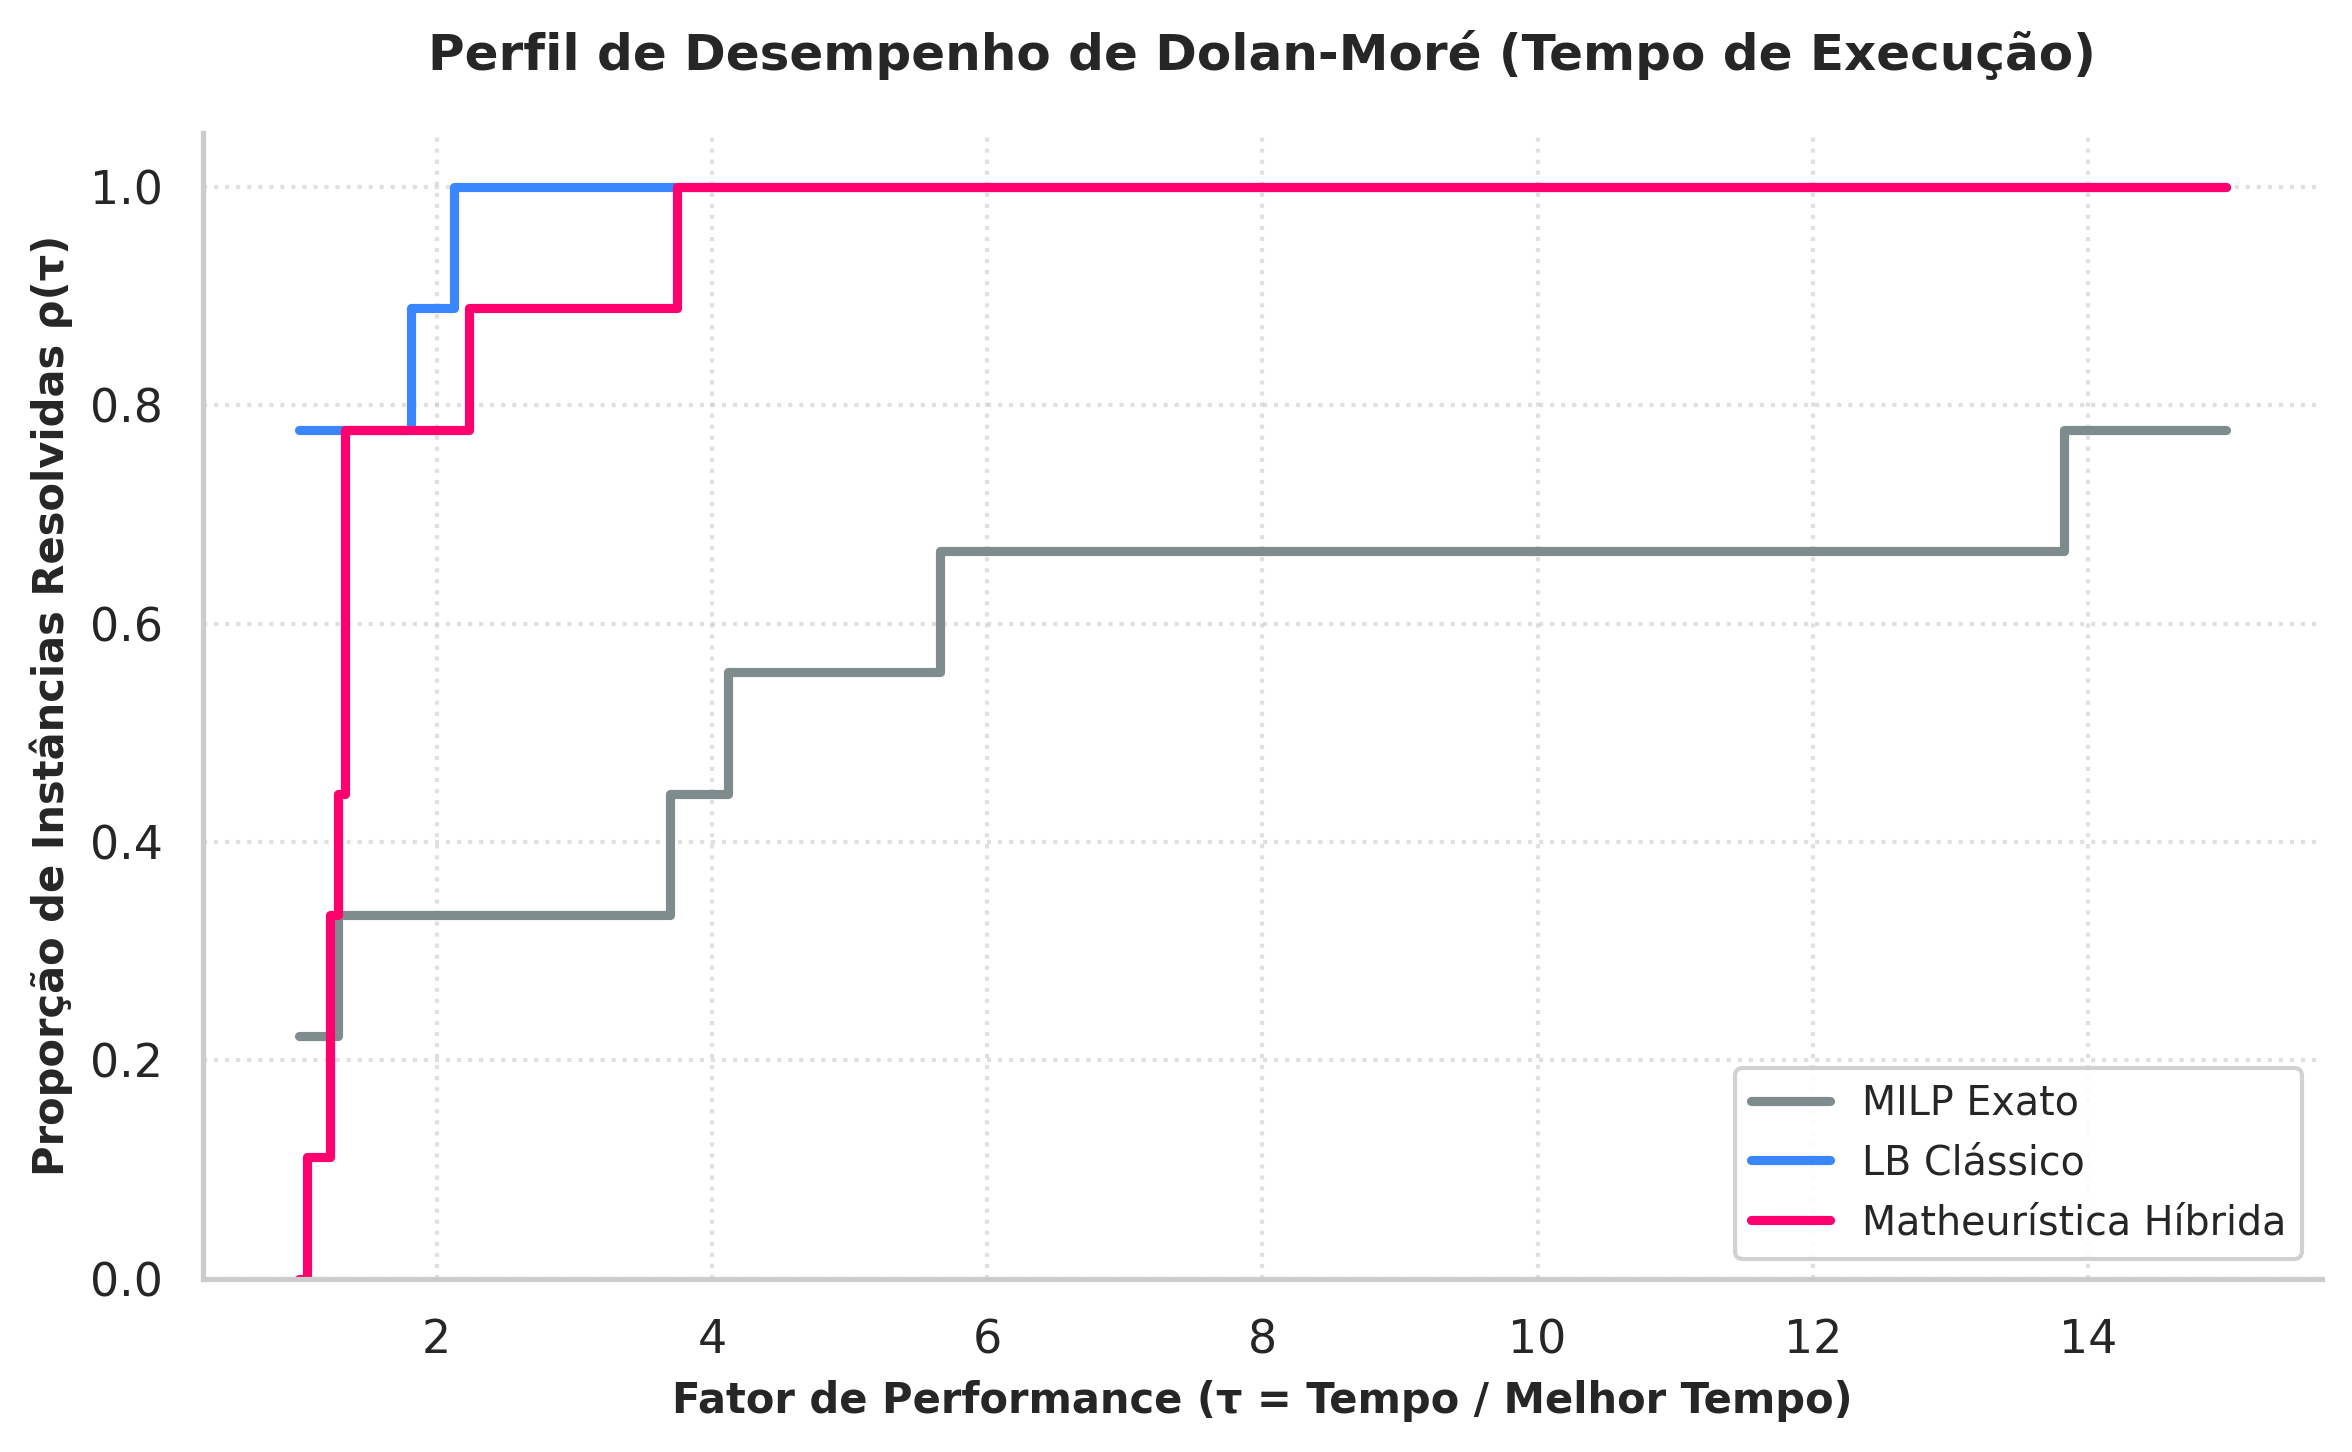

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Configuração de estilo visual
sns.set_theme(style="whitegrid", font="sans-serif")
palette = {
    'MILP Exato': '#7F8C8D',
    'LB Clássico': '#3A86FF',
    'Matheurística Híbrida': '#FF006E'
}

# Dados de tempo de execução
df_time = pd.DataFrame({
    'Algoritmo': ['MILP Exato']*9 + ['LB Clássico']*9 + ['Matheurística Híbrida']*9,
    'Tempo (s)': [357.44, 546.36, 136.78, 91.01, 488.84, 217.21, 6.32, 12.07, 31.44,
                  25.89, 31.74, 33.41, 24.82, 30.06, 38.41, 13.34, 21.73, 25.05,
                  32.60, 41.70, 40.59, 32.82, 36.41, 40.05, 23.61, 26.89, 33.19],
    'Instância': ['set.01', 'set.02', 'set.03', 'set.04', 'set.05', 'set.06', 'set.07', 'set.08', 'set.09']*3
})

# Cálculo do fator de performance tau
time_pivot = df_time.pivot(index='Instância', columns='Algoritmo', values='Tempo (s)')
min_times = time_pivot.min(axis=1)
ratios = time_pivot.divide(min_times, axis=0)

# Construção do gráfico Dolan-Moré
fig, ax = plt.subplots(figsize=(8, 5), dpi=300)
tau_vals = np.linspace(1, 15, 500)

for algo in ['MILP Exato', 'LB Clássico', 'Matheurística Híbrida']:
    r = ratios[algo].values
    probs = [np.mean(r <= t) for t in tau_vals]
    ax.step(tau_vals, probs, label=algo, color=palette[algo], where='post', linewidth=2.2)

ax.set_title('Perfil de Desempenho de Dolan-Moré (Tempo de Execução)', fontsize=12, fontweight='bold', pad=15)
ax.set_xlabel('Fator de Performance (τ = Tempo / Melhor Tempo)', fontsize=10, fontweight='bold')
ax.set_ylabel('Proporção de Instâncias Resolvidas ρ(τ)', fontsize=10, fontweight='bold')
ax.set_ylim(0, 1.05)
ax.grid(True, linestyle=":", alpha=0.6)
ax.legend(loc='lower right', frameon=True, facecolor='white', framealpha=0.9, fontsize=9.5)
sns.despine(top=True, right=True)

plt.tight_layout()
plt.savefig('dolan_more_legivel.png', bbox_inches='tight')
plt.show()

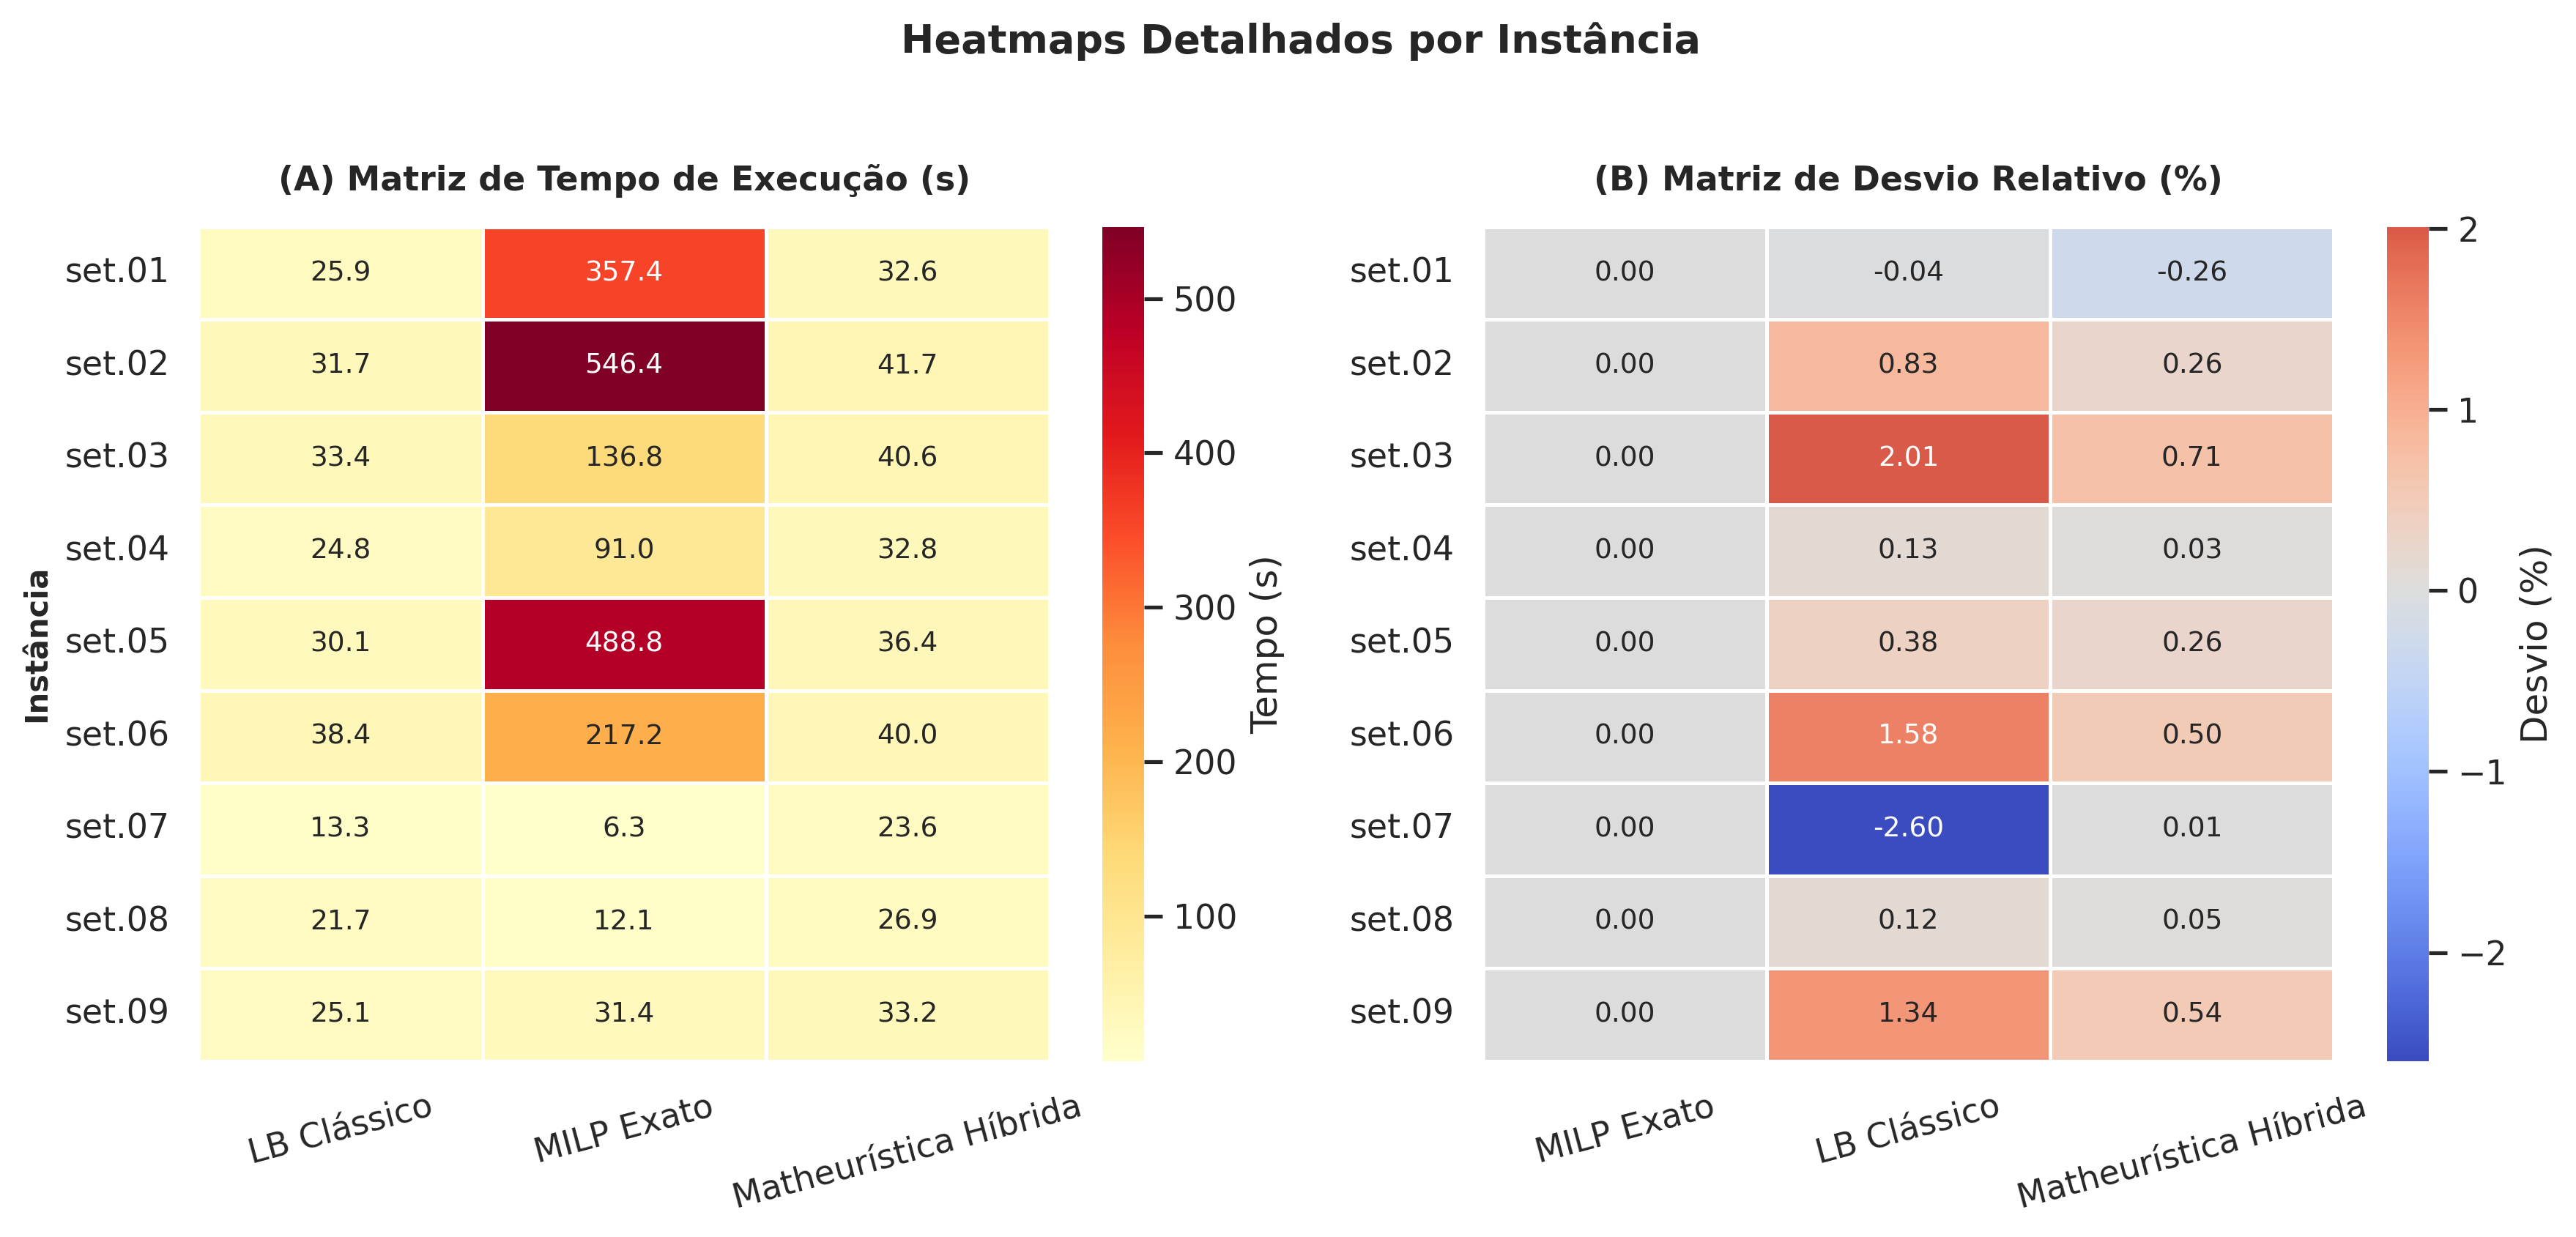

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(style="white", font="sans-serif")

# Preparação das matrizes de tempo e desvio
df_time = pd.DataFrame({
    'Algoritmo': ['MILP Exato']*9 + ['LB Clássico']*9 + ['Matheurística Híbrida']*9,
    'Tempo (s)': [357.44, 546.36, 136.78, 91.01, 488.84, 217.21, 6.32, 12.07, 31.44,
                  25.89, 31.74, 33.41, 24.82, 30.06, 38.41, 13.34, 21.73, 25.05,
                  32.60, 41.70, 40.59, 32.82, 36.41, 40.05, 23.61, 26.89, 33.19],
    'Instância': ['set.01', 'set.02', 'set.03', 'set.04', 'set.05', 'set.06', 'set.07', 'set.08', 'set.09']*3
})

df_dev = pd.DataFrame({
    'Algoritmo': ['LB Clássico']*9 + ['Matheurística Híbrida']*9,
    'Desvio (%)': [-0.04, 0.83, 2.01, 0.13, 0.38, 1.58, -2.60, 0.12, 1.34,
                   -0.26, 0.26, 0.71, 0.03, 0.26, 0.50, 0.01, 0.05, 0.54],
    'Instância': ['set.01', 'set.02', 'set.03', 'set.04', 'set.05', 'set.06', 'set.07', 'set.08', 'set.09']*2
})

time_pivot = df_time.pivot(index='Instância', columns='Algoritmo', values='Tempo (s)')
dev_pivot = df_dev.pivot(index='Instância', columns='Algoritmo', values='Desvio (%)')
dev_pivot['MILP Exato'] = 0.0
dev_pivot = dev_pivot[['MILP Exato', 'LB Clássico', 'Matheurística Híbrida']]

# Construção dos Heatmaps em Subplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5.5), dpi=300)

# (A) Tempo de Execução
sns.heatmap(time_pivot, annot=True, fmt=".1f", cmap="YlOrRd", cbar_kws={'label': 'Tempo (s)'}, ax=ax1, linewidths=0.8, annot_kws={"size": 9})
ax1.set_title('(A) Matriz de Tempo de Execução (s)', fontsize=11, fontweight='bold', pad=12)
ax1.set_xlabel('')
ax1.set_ylabel('Instância', fontsize=10, fontweight='bold')
ax1.tick_params(axis='x', rotation=15)
ax1.tick_params(axis='y', rotation=0)

# (B) Desvio Relativo
sns.heatmap(dev_pivot, annot=True, fmt=".2f", cmap="coolwarm", center=0, cbar_kws={'label': 'Desvio (%)'}, ax=ax2, linewidths=0.8, annot_kws={"size": 9})
ax2.set_title('(B) Matriz de Desvio Relativo (%)', fontsize=11, fontweight='bold', pad=12)
ax2.set_xlabel('')
ax2.set_ylabel('')
ax2.tick_params(axis='x', rotation=15)
ax2.tick_params(axis='y', rotation=0)

plt.suptitle('Heatmaps Detalhados por Instância', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('heatmap_legivel.png', bbox_inches='tight')
plt.show()

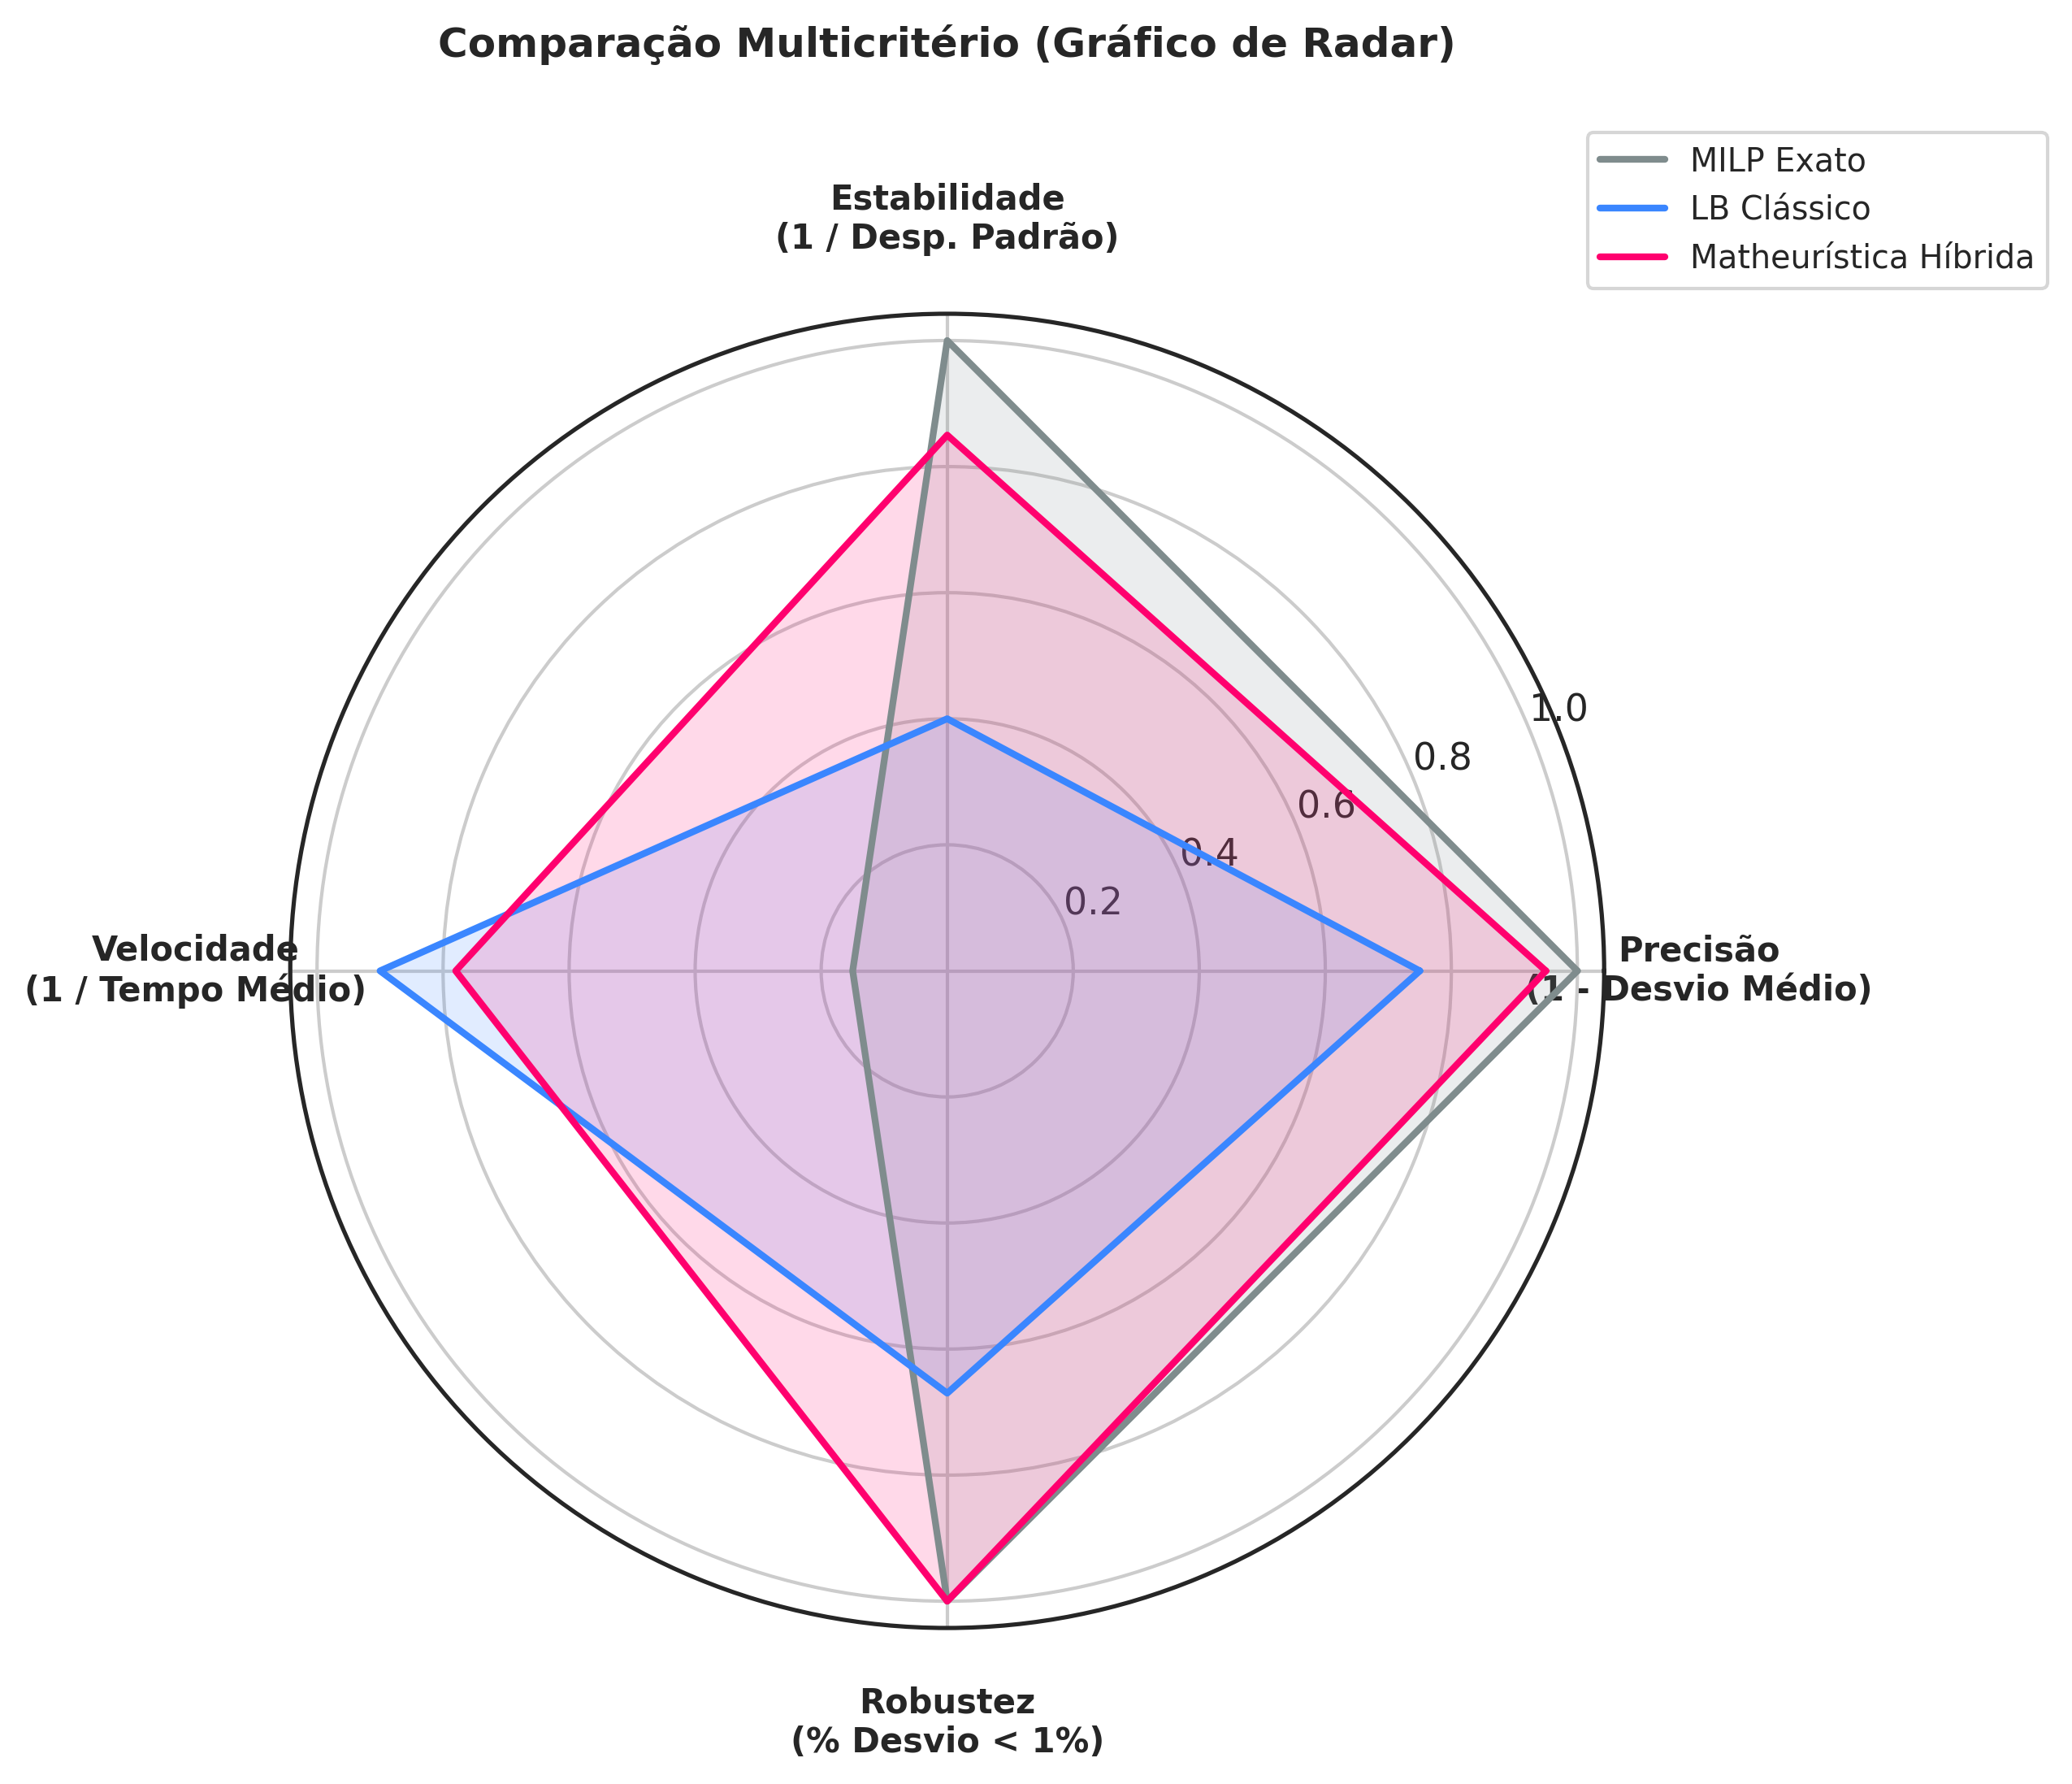

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Paleta de cores
palette = {
    'MILP Exato': '#7F8C8D',
    'LB Clássico': '#3A86FF',
    'Matheurística Híbrida': '#FF006E'
}

# Definição das métricas do Radar
categories = [
    'Precisão\n(1 - Desvio Médio)',
    'Estabilidade\n(1 / Desp. Padrão)',
    'Velocidade\n(1 / Tempo Médio)',
    'Robustez\n(% Desvio < 1%)'
]

metrics = {
    'LB Clássico': [0.75, 0.40, 0.90, 0.67],
    'Matheurística Híbrida': [0.95, 0.85, 0.78, 1.00],
    'MILP Exato': [1.00, 1.00, 0.15, 1.00]
}

N = len(categories)
angles = [n / float(N) * 2 * np.pi for n in range(N)]
angles += angles[:1]

fig, ax = plt.subplots(figsize=(7, 7), subplot_kw=dict(polar=True), dpi=300)

# Ajuste dos rótulos e afastamento para evitar colisões
plt.xticks(angles[:-1], categories, size=10, fontweight='bold')
ax.tick_params(pad=15)

for algo in ['MILP Exato', 'LB Clássico', 'Matheurística Híbrida']:
    values = metrics[algo].copy()
    values += values[:1]
    ax.plot(angles, values, linewidth=2, linestyle='solid', label=algo, color=palette[algo])
    ax.fill(angles, values, color=palette[algo], alpha=0.15)

# Título elevado (y=1.18) e legenda posicionada fora do gráfico
ax.set_title('Comparação Multicritério (Gráfico de Radar)', fontsize=12, fontweight='bold', y=1.18)
ax.legend(loc='upper right', bbox_to_anchor=(1.35, 1.15), frameon=True, fontsize=9.5)

plt.savefig('radar_legivel.png', bbox_inches='tight')
plt.show()